# GENERACIÓN DE BHC CON LongT5

Para este ejercicio se utiliza el modelo Long-T5 de google, un modelo que al igual que Bart, es encoder-decoder. Para este ejercicio se hace uso de la base de datos MIMIC-IV nuevamente, pero esta vez se utiliza tanto MIMIC-IV-NOTES como MIMIC-IV (datos tabulados), son datos de estancias hospitalarias del Centro Médico Beth Israel Deaconess. El objetivo es generar el Brief Hospital Course a partir de una ficha clinica estructurada a partir de código, extrayendo los datos tabulares y escribiendolos como una ficha con los datos escritos en secuencia temporal.

Para este ejercicio la cohorte se busca en las tablas de notas, para la busqueda de grilla se seleccionan 450 pacientes, de los cuales 315 quedan para el entrenamiento. Los pacientes se seleccionan aquellos que tengan una referencia válida de BHC de un máximo de 1024 tokens, ya que el modelo acepta un máximo de 1024 tokens para la salida de referencia, mas de esto obligaria a recortar la referencia, por tanto se escogieron unicamente aquellos cuya referencia pudiera entrar completa. Para el entrenamiento del modelo final se expande la cohorte de 315 pacientes de entrenamiento a 1000.

La entrada del modelo consta de la base de datos de MIMIC-IV, se toman un total de 41 columnas provenientes de 10 tablas que se consideran los datos necesarios para generar el *BHC*. Por otro lado, la salida se extrae de MIMIC-IV-Notes, la cual posee discharge summaries y radiology reports, el BHC hace parte de los discharge summaries, por tanto, se extrae de ahí y se asegura de que tenga un tamaño máximo de 1024.

Se hace uso del modelo LongT5 en lugar de Bart ya que aunque ambos son modelos encoder-decoder, Bart acepta un máximo de 1024 tokens en el input, mientras LongT5 admite hasta 4096, esto permite ingresar mas referencia de entrada, que en muchos casos hubo que recortar.

# INSTALACIONES E IMPORTACIONES


In [1]:
!pip install -q transformers==4.57.1
!pip install -q accelerate==1.11.0
!pip install -q datasets==4.3.0
!pip install -q pandas==2.2.3
!pip install -q scikit-learn==1.6.1
!pip install -q matplotlib
!pip install -q seaborn
!pip install -q google-cloud-bigquery
!pip install -q pandas-gbq
!pip install -q db-dtypes
!pip install -q pyarrow
!pip install -q rouge-score
!pip install -q nltk
!pip install -q sacrebleu
!pip install -q sentencepiece
!pip install -q protobuf


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  P

In [2]:
from google.colab import drive, auth
from google.cloud import bigquery
from google.api_core.exceptions import NotFound
from pathlib import Path
from itertools import product
from inspect import signature
import shutil
from collections import Counter
from hashlib import sha256
from importlib.metadata import version
from transformers.trainer_utils import get_last_checkpoint
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from datasets import Dataset
from transformers import (
    AutoConfig, AutoTokenizer, AutoModelForSeq2SeqLM, PreTrainedModel, PreTrainedTokenizerBase,
    Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq, set_seed,
)
from rouge_score import rouge_scorer
from nltk.translate.meteor_score import meteor_score
from sacrebleu.metrics import BLEU

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import json
import re
import gc
import nltk


# CONSTANTES


In [3]:
PROJECT_ID = "physionet-506416"
PROJECT = "physionet-data"
DATASET_H = "mimiciv_3_1_hosp"
DATASET_N = "mimiciv_note"
TABLE = "admissions"
DRIVE_ROUTE = "/content/drive"
MANUAL_REVIEW_ROUTE = ""
SEED = 42
HOLDOUT_SIZE = 0.30
TEST_SIZE_IN_HOLDOUT = 0.50
MIN_BHC_CHARS = 100
VALID_ANNOTATIONS = ("rule_valid", "manual_valid")
BHC_HEADERS = ("brief hospital course", "hospital course")

MAIN_HEADERS = (
    "name", "patient name", "unit no", "unit number", "admission date", "discharge date",
    "date of birth", "sex", "gender", "service", "allergies", "allergy", "attending",
    "attending physician", "chief complaint", "major surgical or invasive procedure",
    "major surgical or invasive procedures", "history of present illness",
    "past medical history", "social history", "family history", "physical exam",
    "physical examination", "pertinent results", "brief hospital course", "hospital course",
    "medications on admission", "admission medications", "discharge medications",
    "medications at discharge", "discharge disposition", "discharge diagnosis",
    "discharge diagnoses", "discharge condition", "condition at discharge",
    "discharge instructions", "followup instructions", "follow-up instructions",
    "follow up instructions", "addendum",
)

HEADER_ALTERNATIVES = "|".join(
    re.escape(title).replace(r"\ ", r"[ \t]+")
    for title in sorted(MAIN_HEADERS, key = len, reverse = True)
)

HEADER_PATTERN = re.compile(
    rf"(?:^[ \t]*|[ \t]{{2,}})(?P<title>{HEADER_ALTERNATIVES})\.?[ \t]*:",
    re.IGNORECASE | re.MULTILINE,
)

HEADER_ALONE_PATTERN = re.compile(
    rf"^[ \t]*(?P<title>{HEADER_ALTERNATIVES})\.?[ \t]*\r?$",
    re.IGNORECASE | re.MULTILINE,
)

COHORT_ROUTE = ""
NUM_TRAIN_EPOCHS = 2
BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8
WARMUP_RATIO = 0.03
WEIGHT_DECAY = 0.01
N_SEARCH_ADMISSIONS = 60
QUERY_BATCH_SIZE = 100
MAX_LAB_EVENTS = 60
MAX_MEDICATION_EVENTS = 35
MAX_MICROBIOLOGY_EVENTS = 20
TOP_WORDS = 25
REVIEW_EXAMPLES = 5
BOOTSTRAP_SAMPLES = 1000
SPLIT_PRIORITY = {"train": 0, "validation": 1, "test": 2}
MODEL_ID = "google/long-t5-tglobal-base"
MAX_INPUT_LENGTH = 4096
LEARNING_RATES = [1e-5, 2e-5, 3e-5, 5e-5]
WEIGHT_DECAYS = [0.0, 0.01, 0.1]
TRAIN_EPOCHS = [1, 2]
BATCH_SIZES = [1, 2]
WARMUP_RATIOS = [0.03, 0.1]
MAX_NEW_EXPERIMENTS = None
DISK_CHECK_ROUTE = "/content"
MIN_FREE_DISK_GB = 5.0
NUM_BEAMS = 4
NO_REPEAT_NGRAM_SIZE = 3
LENGTH_PENALTY = 1.0

COHORT_SIZE = 450
MIN_TRAIN_EXAMPLES = 200
MAX_BHC_TOKENS = 1024
MAX_TARGET_LENGTH = 1024
MAX_NEW_TOKENS = 1024
COHORT_PAGE_SIZE = 256
RESTART_EXPIRED_QUERY = False
OUTPUT_ROUTE = "/content/drive/MyDrive/MIMIC/Generacion_BHC_LongT5_Cohorte1024_450"


# CONFIGURACIONES

Después de instalar, reiniciar la sesión si Colab lo solicita y ejecutar las importaciones.
Las consultas requieren acceso a MIMIC y un proyecto BigQuery habilitado, como en el piloto.
La lectura y el análisis pueden ejecutarse antes de entrenar; la GPU se exige al cargar el modelo.


In [4]:
drive.mount(DRIVE_ROUTE)
auth.authenticate_user()
client = bigquery.Client(project = PROJECT_ID)
random = np.random.default_rng(SEED)
set_seed(SEED)
output_path = Path(OUTPUT_ROUTE)
output_path.mkdir(parents = True, exist_ok = True)
eda_path = output_path / "analisis"
eda_path.mkdir(exist_ok = True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
package_versions = {name: version(name) for name in ["transformers", "torch", "datasets", "accelerate"]}
display(package_versions)

use_bf16 = (
    torch.cuda.is_available()
    and torch.cuda.get_device_capability()[0] >= 8
    and torch.cuda.is_bf16_supported()
)
training_precision = "bf16" if use_bf16 else "fp32"
print("Precisión de entrenamiento:", training_precision)


Mounted at /content/drive


{'transformers': '4.57.1',
 'torch': '2.14.1+cu130',
 'datasets': '4.3.0',
 'accelerate': '1.11.0'}

Precisión de entrenamiento: bf16


# BASE DE DATOS

La base de datos se consulta a través de BigQuery, con acceso directo desde physionet para tanto los datos tabulares como las notas. Para los datos tabulares se definieron máximos de filas, ya que habia pacientes con números muy grandes de laboratorios, datos microbiológicos, entre otros. Recortar esto permite también incluir los datos tabulares sin recortar secciones enteras.

# EXTRACTOR DE BHC

Para comprobar cada nota se buscan encabezados reconocidos en las notas. Una vez se localiza el encabezado de BHC, se extrae el intervalo en que se encuentra esta sección para su posterior uso.

In [5]:
def find_headers(text: str = "") -> list[tuple[int, int, str]]:
    """
    Localiza los encabezados principales reconocidos en una nota.
    """
    matches = list(HEADER_PATTERN.finditer(text)) + list(HEADER_ALONE_PATTERN.finditer(text))
    headers = set()
    for match in matches:
        title = " ".join(match["title"].lower().split()).rstrip(".")
        headers.add((match.start(), match.end(), title))
    return sorted(headers)


def find_bhc_span(text: str = "", min_chars: int = MIN_BHC_CHARS) -> dict:
    """
    Obtiene un intervalo BHC para construir la cohorte.
    """
    headers = find_headers(text)
    positions = [i for i, header in enumerate(headers) if header[2] in BHC_HEADERS]
    result = {"bhc_start": -1, "bhc_end": -1, "annotation_status": "missing", "reference_source": "rules"}
    if not positions:
        return result
    result["annotation_status"] = "ambiguous"
    if len(positions) != 1:
        return result
    position = positions[0]
    if position + 1 >= len(headers):
        return result
    start = headers[position][1]
    end = headers[position + 1][0]
    while start < end and text[start].isspace():
        start += 1
    while end > start and text[end - 1].isspace():
        end -= 1
    result["bhc_start"], result["bhc_end"] = start, end
    if end - start >= min_chars:
        result["annotation_status"] = "rule_valid"
    return result


# PREPARACIÓN DEL TOKENIZADOR Y PRESUPUESTOS

LongT5 procesa entrada y respuesta como secuencias separadas, por lo que los 4096 tokens de entrada se utilizan únicamente para el input, mientras que la referencia se limita a 1024. La respuesta no resta tokens del encoder, pues van separados.

Las referencias que superan 1024 tokens se excluyen completas de entrenamiento y validación, nunca se recortan.


In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast = True)
tokenizer.padding_side = "right"
model_config = AutoConfig.from_pretrained(MODEL_ID)

def input_ids(clinical_input: str = "") -> list[int]:
    """
    Recibe clinical_input (str), la ficha clínica sin referencia BHC.
    Retorna list[int] con tokens y marcadores especiales para el encoder.
    """
    return tokenizer.encode(clinical_input, add_special_tokens = True, truncation = False, verbose = False)


def fit_input(clinical_input: str = "") -> tuple[str, bool]:
    """
    Recibe clinical_input (str). Retorna el texto ajustado y un indicador de reducción.
    Respeta MAX_INPUT_LENGTH sin consultar la respuesta real ni su longitud.
    """
    if len(input_ids(clinical_input)) <= MAX_INPUT_LENGTH:
        return clinical_input, False
    ids = tokenizer.encode(clinical_input, add_special_tokens = False, verbose = False)
    low, high, best = 0, len(ids), None
    while low <= high:
        keep = (low + high) // 2
        front = int(keep * 0.65)
        back = keep - front
        candidate = tokenizer.decode(ids[:front], skip_special_tokens = True)
        candidate += "\n[Some clinical events omitted to fit the input budget.]\n"
        candidate += tokenizer.decode(ids[-back:], skip_special_tokens = True) if back else ""
        if len(input_ids(candidate)) <= MAX_INPUT_LENGTH:
            best, low = candidate, keep + 1
        else:
            high = keep - 1
    return best, True


def prepare_records(frame: pd.DataFrame, split_name: str, enforce_budget: bool = True) -> tuple[list[dict], pd.DataFrame, pd.DataFrame]:
    """
    Recibe frame (DataFrame) con clinical_input y bhc_text; split_name (str)
    identifica la partición. enforce_budget (bool) excluye referencias largas.
    Retorna pares de texto, metadatos aceptados y auditoría de todos los casos.
    En prueba conserva la referencia íntegra aunque exceda el presupuesto del decoder.
    """
    records, metadata, audit = [], [], []
    for row in frame.to_dict("records"):
        input_text, reduced = fit_input(row["clinical_input"])
        reference = row["bhc_text"].strip()
        target_ids = tokenizer(text_target = reference, truncation = False, verbose = False)["input_ids"]
        target_tokens = len(target_ids)
        original_tokens = len(input_ids(row["clinical_input"]))
        used_tokens = len(input_ids(input_text))
        reason = ""
        if not reference:
            reason = "empty_reference"
        elif enforce_budget and target_tokens > MAX_TARGET_LENGTH:
            reason = "reference_exceeds_output_budget"
        audit.append({"note_id": row["note_id"], "split": split_name,
            "input_tokens_original": original_tokens, "input_tokens_used": used_tokens,
            "input_tokens_removed_net": max(0, original_tokens - used_tokens),
            "input_retention_ratio": used_tokens / max(1, original_tokens),
            "reference_tokens": target_tokens, "input_reduced": reduced,
            "reference_exceeds_output_budget": target_tokens > MAX_TARGET_LENGTH,
            "excluded_reason": reason, "reference_source": row["reference_source"]})
        if reason:
            continue
        records.append({"clinical_input": input_text, "bhc_text": reference})
        metadata.append({"note_id": row["note_id"], "hadm_id": int(row["hadm_id"]),
            "subject_id": int(row["subject_id"]), "reference_source": row["reference_source"],
            "clinical_input": input_text, "reference": reference})
    return records, pd.DataFrame(metadata), pd.DataFrame(audit)


def tokenize_batch(batch: dict) -> dict:
    """
    Recibe batch (dict) con listas clinical_input y bhc_text de pares ya auditados.
    Retorna input_ids, attention_mask y labels; las etiquetas contienen solo BHC.
    No aplica truncamiento ni relleno. El collator rellena cada lote dinámicamente.
    """
    encoded = tokenizer(batch["clinical_input"], truncation = False)
    encoded["labels"] = tokenizer(text_target = batch["bhc_text"], truncation = False)["input_ids"]
    return encoded


def prepare_dataset(records: list[dict]) -> Dataset:
    """
    Recibe records (list[dict]) con fichas y BHC completos que pasaron la auditoría.
    Retorna Dataset tokenizado para entrenamiento o validación de LongT5.
    Las referencias largas de prueba se evalúan desde los metadatos, sin este filtro.
    """
    return Dataset.from_list(records).map(tokenize_batch, batched = True, remove_columns = ["clinical_input", "bhc_text"])


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

# SELECCIÓN DE LA COHORTE

Se conserva una admisión elegible por paciente, se descartan BHC repetidos (si hay). Por reproducibilidad el código guarda la cohorte seleccionada la primera vez para que la siguiente selección tome las mismas notas de pacientes sin tener que consultar nuevamente a las tablas.

In [7]:
def save_selection_state(state: dict, path: Path) -> None:
    """
    Recibe state (dict), con configuración, cursor y registros, y path (Path).
    Guarda el estado en un temporal y reemplaza el archivo al terminar. Retorna None.
    """
    temporary_path = path.with_suffix(".tmp.json")
    temporary_path.write_text(json.dumps(state, ensure_ascii = False), encoding = "utf-8")
    temporary_path.replace(path)


def cohort_settings(cohort_tokenizer: PreTrainedTokenizerBase) -> dict:
    """
    Recibe cohort_tokenizer, el tokenizador utilizado para medir la referencia.
    Retorna dict con la configuración que debe coincidir para reanudar la selección.
    """
    return {"project": PROJECT, "notes_dataset": DATASET_N, "hospital_dataset": DATASET_H,
        "admissions_table": TABLE, "seed": SEED, "tokenizer": cohort_tokenizer.name_or_path,
        "max_bhc_tokens": MAX_BHC_TOKENS, "cohort_size": COHORT_SIZE,
        "min_bhc_chars": MIN_BHC_CHARS, "header_pattern": HEADER_PATTERN.pattern,
        "header_alone_pattern": HEADER_ALONE_PATTERN.pattern, "selection_version": 1}


def start_cohort_query(query_client: bigquery.Client) -> object:
    """
    Recibe query_client (bigquery.Client), autenticado en el proyecto del usuario.
    Retorna el trabajo de una consulta ordenada sobre la población completa de notas.
    No descarga todos los textos a RAM ni aplica LIMIT antes del filtro BHC.
    """
    query_cohort = f"""
    SELECT d.note_id, d.subject_id, d.hadm_id, d.note_seq, d.text
    FROM `{PROJECT}.{DATASET_N}.discharge` AS d
    WHERE d.subject_id IS NOT NULL AND d.hadm_id IS NOT NULL
      AND d.note_id IS NOT NULL AND d.text IS NOT NULL
      AND EXISTS (
          SELECT 1 FROM `{PROJECT}.{DATASET_H}.{TABLE}` AS a
          WHERE a.hadm_id = d.hadm_id AND a.subject_id = d.subject_id
      )
    ORDER BY
        FARM_FINGERPRINT(CONCAT(CAST(d.subject_id AS STRING), ':', CAST(@seed AS STRING))),
        d.subject_id, d.hadm_id, LENGTH(d.text) DESC, d.note_seq, d.note_id
    """
    job_config = bigquery.QueryJobConfig(query_parameters = [
        bigquery.ScalarQueryParameter("seed", "INT64", SEED),
    ])
    return query_client.query(query_cohort, job_config = job_config)


def bhc_candidate(row: dict, cohort_tokenizer: PreTrainedTokenizerBase) -> tuple[dict | None, str]:
    """
    Recibe row (dict) con las cinco columnas de una nota y cohort_tokenizer.
    Retorna un registro con referencia completa o None, junto al motivo de exclusión.
    Cuenta los marcadores especiales y nunca recorta la referencia para aceptarla.
    """
    text = row["text"]
    annotation = find_bhc_span(text)
    if annotation["annotation_status"] not in VALID_ANNOTATIONS:
        return None, annotation["annotation_status"]
    bhc = text[annotation["bhc_start"]:annotation["bhc_end"]].strip()
    token_count = len(cohort_tokenizer(text_target = bhc, truncation = False, verbose = False)["input_ids"])
    if not bhc or token_count > MAX_BHC_TOKENS:
        return None, "reference_exceeds_output_budget"
    return {"note_id": str(row["note_id"]), "subject_id": int(row["subject_id"]),
        "hadm_id": int(row["hadm_id"]), "note_seq": int(row["note_seq"]) if row["note_seq"] is not None else 0,
        "text": text, **annotation, "bhc_text": bhc, "bhc_tokens": token_count}, "accepted"


def validate_cohort_records(records: list[dict], cohort_tokenizer: PreTrainedTokenizerBase) -> None:
    """
    Recibe records (list[dict]) guardados y cohort_tokenizer.
    Comprueba unicidad, correspondencia entre texto y offsets y presupuesto real.
    Retorna None; detiene la selección si el respaldo es inconsistente.
    """
    patients, note_ids, references = set(), set(), set()
    for row in records:
        patient = int(row["subject_id"])
        digest = sha256(" ".join(row["bhc_text"].lower().split()).encode()).hexdigest()
        start, end = int(row["bhc_start"]), int(row["bhc_end"])
        count = len(cohort_tokenizer(text_target = row["bhc_text"], truncation = False, verbose = False)["input_ids"])
        patients.add(patient)
        note_ids.add(row["note_id"])
        references.add(digest)


def select_bhc_cohort(
    query_client: bigquery.Client, cohort_tokenizer: PreTrainedTokenizerBase, state_path: Path,
) -> tuple[pd.DataFrame, dict]:
    """
    Recibe cliente BigQuery, tokenizador y state_path (Path), el respaldo de selección.
    Retorna DataFrame de la cohorte completa y dict con cursor y auditoría.
    Reanuda el mismo trabajo por páginas. No entrena, borra archivos ni filtra el input.
    """
    settings = cohort_settings(cohort_tokenizer)
    if state_path.exists():
        state = json.loads(state_path.read_text(encoding = "utf-8"))
        validate_cohort_records(state["records"], cohort_tokenizer)
    else:
        job = start_cohort_query(query_client)
        state = {"settings": settings, "job_id": job.job_id, "location": job.location,
            "processed_rows": 0, "records": [], "stats": {}}
        save_selection_state(state, state_path)

    records = state["records"]
    if len(records) > COHORT_SIZE:
        raise ValueError("El respaldo supera el tamaño de cohorte configurado.")
    if len(records) == COHORT_SIZE:
        print("Se recupera la cohorte completa guardada; no se lanza otra consulta.")
        return pd.DataFrame(records), state

    def result_rows() -> object:
        """No recibe argumentos. Retorna páginas desde el cursor del trabajo guardado."""
        job = query_client.get_job(state["job_id"], location = state["location"])
        return job.result(page_size = COHORT_PAGE_SIZE, start_index = state["processed_rows"])

    try:
        rows = result_rows()
    except NotFound as error:
        if not RESTART_EXPIRED_QUERY:
            raise RuntimeError("No están disponibles el trabajo o sus resultados. Los casos guardados se conservan. Para repetir la consulta desde el inicio establece RESTART_EXPIRED_QUERY=True.") from error
        print("Se reinicia una consulta expirada; puede tener coste de BigQuery. Se conservan los casos guardados.")
        job = start_cohort_query(query_client)
        state.update(job_id = job.job_id, location = job.location, processed_rows = 0, stats = {})
        save_selection_state(state, state_path)
        rows = result_rows()

    patients = {int(row["subject_id"]) for row in records}
    hashes = {sha256(" ".join(row["bhc_text"].lower().split()).encode()).hexdigest() for row in records}
    try:
        for page in rows.pages:
            for raw in page:
                if int(raw["subject_id"]) in patients:
                    reason = "patient_already_selected"
                else:
                    candidate, reason = bhc_candidate(raw, cohort_tokenizer)
                    if candidate is not None:
                        digest = sha256(" ".join(candidate["bhc_text"].lower().split()).encode()).hexdigest()
                        if digest in hashes:
                            reason = "duplicate_bhc"
                        else:
                            records.append(candidate)
                            patients.add(candidate["subject_id"])
                            hashes.add(digest)
                state["processed_rows"] += 1
                state["stats"][reason] = state["stats"].get(reason, 0) + 1
                if len(records) >= COHORT_SIZE:
                    break
            save_selection_state(state, state_path)
            print(f"Filas revisadas: {state['processed_rows']} | Casos elegibles: {len(records)}/{COHORT_SIZE}")
            if len(records) >= COHORT_SIZE:
                break
    except BaseException:
        try:
            save_selection_state(state, state_path)
        except OSError:
            print("No se pudo guardar el último avance. Se conserva el último estado persistido.")
        raise

    validate_cohort_records(records, cohort_tokenizer)
    if len(records) < COHORT_SIZE:
        raise ValueError(f"La consulta terminó con {len(records)} casos elegibles de {COHORT_SIZE}. El respaldo se conserva; no se inicia entrenamiento con una cohorte incompleta.")
    return pd.DataFrame(records), state


In [8]:
cohort_path = output_path / f"cohorte_bhc_{MAX_BHC_TOKENS}_{COHORT_SIZE}"
cohort_path.mkdir(parents = True, exist_ok = True)
state_path = cohort_path / "EstadoSeleccion.json"

cohort, selection_state = select_bhc_cohort(client, tokenizer, state_path)
cohort.to_csv(cohort_path / "Cohorte_BHC.csv.gz", index = False, compression = "gzip")
selection_audit = pd.DataFrame([
    {"reason": reason, "rows": count} for reason, count in selection_state["stats"].items()
])
selection_audit.to_csv(cohort_path / "AuditoriaSeleccion.csv", index = False)
display(selection_audit)
display(cohort["bhc_tokens"].describe())
print("Pacientes seleccionados:", cohort["subject_id"].nunique())
print("Cohorte guardada en:", cohort_path)


Se recupera la cohorte completa guardada; no se lanza otra consulta.


,reason,rows
0,accepted,450
1,patient_already_selected,426
2,missing,69
3,reference_exceeds_output_budget,86
4,ambiguous,6


,bhc_tokens
count,450.000000
mean,465.444444
std,239.770357
min,48.000000
25%,275.250000
50%,426.500000
75%,625.750000
max,1022.000000


Pacientes seleccionados: 450
Cohorte guardada en: /content/drive/MyDrive/MIMIC/Generacion_BHC_LongT5_Cohorte1024_450/cohorte_bhc_1024_450


# LECTURA DE LAS NOTAS SELECCIONADAS


Una vez escogida la cohorte, se seleccionan las notas de dicha cohorte y se guardan en csv.

In [9]:
notes_selected = cohort[["note_id", "subject_id", "hadm_id", "note_seq", "text"]].copy()
notes_snapshot_path = output_path / "NotasSeleccionadas.csv.gz"
if not notes_snapshot_path.exists():
    notes_selected.to_csv(notes_snapshot_path, index = False, compression = "gzip")
print(f"Notas seleccionadas: {len(notes_selected)}")
print("Estado de selección:", state_path)
print("Copia inicial de las notas:", notes_snapshot_path)


Notas seleccionadas: 450
Estado de selección: /content/drive/MyDrive/MIMIC/Generacion_BHC_LongT5_Cohorte1024_450/cohorte_bhc_1024_450/EstadoSeleccion.json
Copia inicial de las notas: /content/drive/MyDrive/MIMIC/Generacion_BHC_LongT5_Cohorte1024_450/NotasSeleccionadas.csv.gz


# LIMPIEZA DE LA BASE DE DATOS


Se eliminan duplicados en caso de existir, se convierten identificadores númericos en números, el texto se asegura de que esté en str. Elimina todas las filas donde el texto de salida sea comillas vacias `""`.

Aunque este proceso resultó en eliminar 0 filas, era necesario realizarlo en caso de encontrar algo que no debiera estar.

In [10]:
raw_note_count = len(notes_selected)
notes_selected["subject_id"] = pd.to_numeric(notes_selected["subject_id"], errors = "coerce")
notes_selected["note_seq"] = pd.to_numeric(notes_selected["note_seq"], errors = "coerce").fillna(0)
notes_selected = notes_selected.dropna(subset = ["subject_id", "hadm_id", "text"]).copy()
notes_selected["text"] = notes_selected["text"].astype(str)
notes_selected = notes_selected.loc[notes_selected["text"].str.strip().ne("")].copy()
notes_selected["subject_id"] = notes_selected["subject_id"].astype(np.int64)
notes_selected["hadm_id"] = notes_selected["hadm_id"].astype(np.int64)
notes_selected["note_id"] = notes_selected["note_id"].astype(str)
notes_selected["text_length"] = notes_selected["text"].str.len()

notes_selected = (
    notes_selected.sort_values(
        ["hadm_id", "text_length", "note_seq", "note_id"],
        ascending = [True, False, True, True], kind = "mergesort",
    )
    .drop_duplicates(subset = ["hadm_id"], keep = "first")
    .drop(columns = ["text_length"])
    .reset_index(drop = True)
)
if notes_selected.empty or not notes_selected["note_id"].is_unique:
    raise ValueError("No quedaron notas válidas o hay note_id duplicados.")
if notes_selected["subject_id"].nunique() < 10:
    raise ValueError("Hay pocos pacientes para las particiones. Revisa COHORT_SIZE y las referencias.")

print(f"Notas finales: {len(notes_selected)}")
print(f"Pacientes únicos: {notes_selected['subject_id'].nunique()}")

clean_note_count = len(notes_selected)
notes_selected["note_hash"] = notes_selected["text"].map(
    lambda text: sha256(" ".join(text.lower().split()).encode()).hexdigest()
)
duplicate_notes = notes_selected.loc[notes_selected.duplicated("note_hash", keep = False)]
duplicate_notes[["note_id", "subject_id", "hadm_id", "note_hash"]].to_csv(
    eda_path / "NotasDuplicadas.csv", index = False,
)
notes_selected = notes_selected.drop_duplicates("note_hash").reset_index(drop = True)


Notas finales: 450
Pacientes únicos: 450


# APLICACIÓN DE LAS REFERENCIAS BHC

Se aplican funciones para asegurarse que el BHC si se encuentre realmente en la nota.

In [11]:
annotations = pd.DataFrame([find_bhc_span(text) for text in notes_selected["text"]])
notes_selected = pd.concat([notes_selected, annotations], axis = 1)
display(notes_selected["annotation_status"].value_counts().rename_axis("estado").to_frame("notas"))


,notas
estado,
rule_valid,450


# DIVISIÓN DE LOS DATOS

Se separan pacientes aproximadamente en 70/15/15. Las notas y BHC idénticos ya se depuraron antes de la separación.


In [15]:
partitions_path = output_path / "Particiones.csv"
partition_settings = {"seed": SEED, "holdout_size": HOLDOUT_SIZE,
    "test_size_in_holdout": TEST_SIZE_IN_HOLDOUT}
partition_signature = sha256(json.dumps({"settings": partition_settings,
    "notes": notes_selected[["note_id", "subject_id", "hadm_id"]].sort_values("note_id").to_dict("records")}, sort_keys = True).encode()).hexdigest()
partition_config_path = output_path / "ConfiguracionParticiones.json"
if partitions_path.exists():
    saved_partitions = pd.read_csv(partitions_path, dtype = {"note_id": str})
    notes_selected["split"] = notes_selected["note_id"].map(saved_partitions.set_index("note_id")["split"])
else:
    splitter = GroupShuffleSplit(n_splits = 1, test_size = HOLDOUT_SIZE, random_state = SEED)
    train_indices, holdout_indices = next(splitter.split(notes_selected, groups = notes_selected["subject_id"]))
    holdout = notes_selected.iloc[holdout_indices]
    splitter_holdout = GroupShuffleSplit(n_splits = 1, test_size = TEST_SIZE_IN_HOLDOUT, random_state = SEED)
    validation_indices, test_indices = next(splitter_holdout.split(holdout, groups = holdout["subject_id"]))
    notes_selected["split"] = ""
    notes_selected.loc[notes_selected.index[train_indices], "split"] = "train"
    notes_selected.loc[holdout.index[validation_indices], "split"] = "validation"
    notes_selected.loc[holdout.index[test_indices], "split"] = "test"

notes_selected[["note_id", "subject_id", "hadm_id", "split", "reference_source"]].to_csv(partitions_path, index = False)
partition_config_path.write_text(json.dumps({"signature": partition_signature, "settings": partition_settings}, indent = 2), encoding = "utf-8")
display(notes_selected.groupby("split").agg(notas = ("note_id", "size"), pacientes = ("subject_id", "nunique")))


,notas,pacientes
split,,
test,68,68
train,315,315
validation,67,67


In [16]:
if COHORT_ROUTE:
    candidate_cohort = pd.read_csv(COHORT_ROUTE, dtype = {"note_id": str})
    accepted_ids = set(candidate_cohort.loc[
        candidate_cohort["candidate"].astype(str).str.lower().isin(["true", "1"]), "note_id"
    ])
    notes_selected["cohort_accepted"] = notes_selected["note_id"].isin(accepted_ids)
else:
    notes_selected["cohort_accepted"] = True
notes_selected["selected_for_training"] = (
    notes_selected["split"].eq("train") & notes_selected["cohort_accepted"]
)


# LECTURA DE DATOS CLÍNICOS

Se seleccionan las 41 columnas y 10 filas de la entrada para todos los pacientes que hacen parte de la cohorte.


In [17]:
gen_requested_ids = sorted(notes_selected["hadm_id"].astype(int).unique().tolist())
query = f"""
WITH selected_admissions AS (
    SELECT
        subject_id,
        hadm_id,
        admittime,
        dischtime,
        admission_type,
        admission_location,
        discharge_location
    FROM `{PROJECT}.{DATASET_H}.admissions`
    WHERE hadm_id IN UNNEST(@selected_ids)
)

SELECT
    a.*,

    -- Información del paciente
    p.gender,
    p.anchor_age,
    p.anchor_year,

    -- Diagnósticos
    ARRAY(
        SELECT AS STRUCT
            d.icd_code,
            d.icd_version,
            d.seq_num,
            dd.long_title
        FROM `{PROJECT}.{DATASET_H}.diagnoses_icd` d
        LEFT JOIN `{PROJECT}.{DATASET_H}.d_icd_diagnoses` dd
            ON d.icd_code = dd.icd_code
            AND d.icd_version = dd.icd_version
        WHERE d.hadm_id = a.hadm_id
    ) AS diagnoses,

    -- Laboratorios
    ARRAY(
        SELECT AS STRUCT
            l.itemid,
            l.charttime,
            l.valuenum,
            l.value,
            l.valueuom,
            l.ref_range_lower,
            l.ref_range_upper,
            l.flag,
            dl.label,
            dl.fluid,
            dl.category
        FROM `{PROJECT}.{DATASET_H}.labevents` l
        LEFT JOIN `{PROJECT}.{DATASET_H}.d_labitems` dl
            ON l.itemid = dl.itemid
        WHERE l.hadm_id = a.hadm_id
          AND (l.charttime IS NULL OR l.charttime <= a.dischtime)
          AND (l.storetime IS NULL OR l.storetime <= a.dischtime)
    ) AS labs,

    -- Prescripciones
    ARRAY(
        SELECT AS STRUCT
            drug,
            dose_val_rx,
            dose_unit_rx,
            route,
            starttime,
            stoptime
        FROM `{PROJECT}.{DATASET_H}.prescriptions` rx
        WHERE rx.hadm_id = a.hadm_id
    ) AS prescriptions,

    -- Microbiología
    ARRAY(
        SELECT AS STRUCT
            charttime,
            spec_type_desc,
            test_name,
            org_name,
            ab_name,
            interpretation
        FROM `{PROJECT}.{DATASET_H}.microbiologyevents` m
        WHERE m.hadm_id = a.hadm_id
          AND (m.charttime IS NULL OR m.charttime <= a.dischtime)
          AND (m.storetime IS NULL OR m.storetime <= a.dischtime)
    ) AS microbiology,

    -- Procedimientos
    ARRAY(
        SELECT AS STRUCT
            pr.icd_code,
            pr.icd_version,
            pr.seq_num,
            dp.long_title
        FROM `{PROJECT}.{DATASET_H}.procedures_icd` pr
        LEFT JOIN `{PROJECT}.{DATASET_H}.d_icd_procedures` dp
            ON pr.icd_code = dp.icd_code
            AND pr.icd_version = dp.icd_version
        WHERE pr.hadm_id = a.hadm_id
    ) AS procedures

FROM selected_admissions a
LEFT JOIN `{PROJECT}.{DATASET_H}.patients` p
    ON a.subject_id = p.subject_id
"""


gen_chunks = []
for _offset in range(0, len(gen_requested_ids), QUERY_BATCH_SIZE):
    _batch_ids = gen_requested_ids[_offset:_offset + QUERY_BATCH_SIZE]
    _job_config = bigquery.QueryJobConfig(query_parameters=[
        bigquery.ArrayQueryParameter('selected_ids', 'INT64', _batch_ids),
    ])
    _part = client.query(query, job_config=_job_config).to_dataframe(create_bqstorage_client=False)
    gen_chunks.append(_part)

clinical_data = pd.concat(gen_chunks, ignore_index=True)
if clinical_data['hadm_id'].duplicated().any():
    raise ValueError('BigQuery devolvió admisiones duplicadas.')
gen_missing_ids = sorted(set(gen_requested_ids) - set(clinical_data['hadm_id'].astype(int)))
pd.DataFrame({'hadm_id': gen_missing_ids}).to_csv(output_path / 'missing_tabular_admissions.csv', index=False)
if clinical_data.empty:
    raise ValueError('La consulta no recuperó admisiones. Revise versiones, permisos y proyecto BigQuery.')
print('Admisiones recuperadas:', len(clinical_data), '| sin datos:', len(gen_missing_ids))


Admisiones recuperadas: 450 | sin datos: 0


# PREPARACIÓN DE LA FICHA CLÍNICA

Se incluyen por analito del primer, mínimo, máximo y ultimo resultado. Lo límites para evitar entradas sin control de tamaño se dan desde la definición de constantes.

In [18]:
def clinical_is_missing(value: object) -> bool:
    """
    Comprueba si un dato está ausente sin confundir listas con escalares.
    """
    if value is None:
        return True
    if isinstance(value, str):
        return value.strip().lower() in {'', 'nan', 'none', 'null', 'nat'}
    if isinstance(value, (float, np.floating)):
        return bool(np.isnan(value))
    try:
        missing = pd.isna(value)
        return bool(missing) if isinstance(missing, (bool, np.bool_)) else False
    except (TypeError, ValueError):
        return False

def clinical_text(value: object) -> str:
    """
      Convierte un dato clínico a texto y retira espacios exteriores.
    """
    if clinical_is_missing(value):
        return ''
    return str(value).strip()

def clinical_records(value: object) -> list[dict]:
    """
    Recibe value (object), un ARRAY clínico, una lista o un registro de BigQuery.
    Retorna list[dict] en orden estable, incluso si la consulta cambia su orden.
    El desempate evita que eventos con la misma hora produzcan entradas distintas.
    """
    if clinical_is_missing(value):
        return []
    if isinstance(value, dict):
        records = [value]
    else:
        if isinstance(value, np.ndarray):
            value = value.tolist()
        if isinstance(value, (list, tuple, pd.Series)):
            records = [dict(item) for item in value if hasattr(item, "items")]
        elif hasattr(value, "items"):
            records = [dict(value)]
        else:
            records = []
    return sorted(records, key = lambda record: json.dumps(
        record, sort_keys = True, default = str, ensure_ascii = False,
    ))

def clinical_number(value: object) -> float | None:
    """
      Convierte un resultado a número cuando es posible.
    """
    if clinical_is_missing(value):
        return None
    try:
        return float(value)
    except (TypeError, ValueError):
        return None

def clinical_fmt(value: object) -> str:
    """
      Representa un valor sin añadir precisión numérica inexistente.
    """
    if clinical_is_missing(value):
        return ''
    if isinstance(value, (float, np.floating)):
        return f'{float(value):g}'
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    return str(value).strip()

def clinical_parse_time(value: object) -> pd.Timestamp | None:
    """
      Convierte una fecha a Timestamp sin zona horaria.
    """
    if clinical_is_missing(value):
        return None
    parsed = pd.to_datetime(value, errors='coerce')
    if pd.isna(parsed):
        return None
    if getattr(parsed, 'tzinfo', None) is not None:
        parsed = parsed.tz_localize(None)
    return parsed

def clinical_time_label(event_time: object, admission_time: object) -> str:
    """
      Representa el tiempo de un evento respecto del ingreso.
    """
    if event_time is None or admission_time is None:
        return 'time not recorded'
    minutes = int((event_time - admission_time).total_seconds() // 60)
    day = minutes // (24 * 60)
    minute_of_day = minutes % (24 * 60)
    return f'D{day:+d} {minute_of_day // 60:02d}:{minute_of_day % 60:02d}'

def clinical_within_stay(event_time: object, discharge_time: object) -> bool:
    """
      Comprueba que el evento no sea posterior al alta.
    """
    return event_time is None or discharge_time is None or event_time <= discharge_time

def clinical_timestamp_rank(event_time: object) -> float:
    """
      Obtiene un valor temporal para ordenar eventos.
    """
    return event_time.timestamp() if event_time is not None else float('-inf')

def clinical_compact_labs(value: object, discharge_time: object) -> tuple[list[dict], int]:
    """
      Selecciona resultados que describen la evolución de cada analito.
    """
    grouped = {}
    for record in clinical_records(value):
        label = clinical_text(record.get('label')) or clinical_text(record.get('itemid')) or 'Unlabelled test'
        fluid = clinical_text(record.get('fluid'))
        event_time = clinical_parse_time(record.get('charttime'))
        if not clinical_within_stay(event_time, discharge_time):
            continue
        result = clinical_fmt(record.get('valuenum')) or clinical_text(record.get('value'))
        if not result:
            continue
        unit = clinical_text(record.get('valueuom'))
        flag = clinical_text(record.get('flag'))
        low = clinical_fmt(record.get('ref_range_lower'))
        high = clinical_fmt(record.get('ref_range_upper'))
        numeric_result = clinical_number(record.get('valuenum'))
        numeric_low = clinical_number(record.get('ref_range_lower'))
        numeric_high = clinical_number(record.get('ref_range_upper'))
        outside_range = numeric_result is not None and (numeric_low is not None and numeric_result < numeric_low or (numeric_high is not None and numeric_result > numeric_high))
        abnormal = outside_range or flag.lower() not in {'', 'normal', 'n', 'none'}
        ref = f'; ref {low}-{high}' if low or high else ''
        flag_text = flag if flag else 'outside reference range' if outside_range else ''
        detail = f'{label}'
        if fluid:
            detail += f' ({fluid})'
        detail += f' = {result}'
        if unit:
            detail += f' {unit}'
        if flag_text:
            detail += f' [{flag_text}{ref}]'
        elif ref:
            detail += f" [{ref.lstrip('; ')}]"
        key = (label.lower(), fluid.lower())
        grouped.setdefault(key, []).append({'time': event_time, 'text': detail, 'abnormal': abnormal, 'numeric': numeric_result})
    candidates = []
    for records in grouped.values():
        records.sort(key=lambda item: (item['time'] is not None, item['time'] or pd.Timestamp.min))
        chosen = [records[0], records[-1]]
        numeric_records = [item for item in records if item.get('numeric') is not None]
        if numeric_records:
            chosen += [min(numeric_records, key=lambda item: item['numeric']), max(numeric_records, key=lambda item: item['numeric'])]
        seen = set()
        for item in chosen:
            signature = (item['time'], item['text'])
            if signature in seen:
                continue
            seen.add(signature)
            candidates.append(item)
    candidates.sort(key=lambda item: (item['abnormal'], clinical_timestamp_rank(item['time'])), reverse=True)
    omitted = max(0, len(candidates) - MAX_LAB_EVENTS)
    candidates = candidates[:MAX_LAB_EVENTS]
    candidates.sort(key=lambda item: (item['time'] is None, item['time'] or pd.Timestamp.max))
    return (candidates, omitted)

def clinical_compact_medications(value: object, admission_time: object, discharge_time: object) -> tuple[list[dict], int]:
    """
      Retira órdenes repetidas y limita los eventos de prescripción.
    """
    events = []
    seen = set()
    for record in clinical_records(value):
        drug = clinical_text(record.get('drug'))
        if not drug:
            continue
        start = clinical_parse_time(record.get('starttime'))
        stop = clinical_parse_time(record.get('stoptime'))
        if not clinical_within_stay(start, discharge_time):
            continue
        dose = ' '.join((part for part in (clinical_text(record.get('dose_val_rx')), clinical_text(record.get('dose_unit_rx'))) if part))
        route = clinical_text(record.get('route'))
        details = [part for part in (dose, route) if part]
        line = f'Medication order: {drug}'
        if details:
            line += f" ({'; '.join(details)})"
        if start is not None or stop is not None:
            line += f'; {clinical_time_label(start, admission_time)} to {clinical_time_label(stop, admission_time)}'
        signature = (drug.lower(), dose.lower(), route.lower(), start, stop)
        if signature in seen:
            continue
        seen.add(signature)
        events.append({'time': start or stop, 'text': line, 'priority': 0})
    events.sort(key=lambda item: (item['time'] is None, item['time'] or pd.Timestamp.max))
    omitted = max(0, len(events) - MAX_MEDICATION_EVENTS)
    return (events[:MAX_MEDICATION_EVENTS], omitted)

def clinical_compact_microbiology(value: object, discharge_time: object) -> tuple[list[dict], int]:
    """
      Retira resultados repetidos y limita los eventos de microbiología.
    """
    events = []
    seen = set()
    for record in clinical_records(value):
        event_time = clinical_parse_time(record.get('charttime'))
        if not clinical_within_stay(event_time, discharge_time):
            continue
        test = clinical_text(record.get('test_name')) or 'Microbiology test'
        sample = clinical_text(record.get('spec_type_desc'))
        organism = clinical_text(record.get('org_name'))
        antibiotic = clinical_text(record.get('ab_name'))
        interpretation = clinical_text(record.get('interpretation'))
        parts = [test]
        if sample:
            parts.append(f'sample: {sample}')
        if organism:
            parts.append(f'organism: {organism}')
        if antibiotic:
            result = f'{antibiotic} susceptibility'
            if interpretation:
                result += f' {interpretation}'
            parts.append(result)
        elif interpretation:
            parts.append(interpretation)
        line = 'Microbiology: ' + '; '.join(parts)
        signature = (event_time, line.lower())
        if signature in seen:
            continue
        seen.add(signature)
        events.append({'time': event_time, 'text': line, 'priority': 1})
    events.sort(key=lambda item: (item['time'] is None, item['time'] or pd.Timestamp.max))
    omitted = max(0, len(events) - MAX_MICROBIOLOGY_EVENTS)
    return (events[:MAX_MICROBIOLOGY_EVENTS], omitted)

def clinical_coded_lines(value: object) -> list[str]:
    """
      Convierte diagnósticos o procedimientos codificados en líneas de texto.
    """
    records = clinical_records(value)
    records.sort(key=lambda record: clinical_number(record.get('seq_num')) or float('inf'))
    lines = []
    seen = set()
    for record in records:
        code = clinical_text(record.get('icd_code'))
        version = clinical_text(record.get('icd_version'))
        title = clinical_text(record.get('long_title'))
        label = title or code or 'Unspecified'
        if code:
            prefix = f'ICD-{version} ' if version else 'ICD '
            label = f'{prefix}{code} — {label}'
        key = label.lower()
        if key not in seen:
            lines.append(label)
            seen.add(key)
    return lines

def gen_build_clinical_input(row: pd.Series | dict) -> str:
    """
      Construye la ficha usando exclusivamente columnas de datos estructurados.
    """
    get = row.get if hasattr(row, 'get') else lambda key, default=None: default
    admission_time = clinical_parse_time(get('admittime'))
    discharge_time = clinical_parse_time(get('dischtime'))
    lines = ['PATIENT AND ADMISSION']
    age = clinical_fmt(get('anchor_age'))
    gender = clinical_text(get('gender'))
    if age:
        lines.append(f'- Age at deidentified anchor year: {age} years')
    if gender:
        lines.append(f'- Sex: {gender}')
    admission_type = clinical_text(get('admission_type'))
    admission_location = clinical_text(get('admission_location'))
    discharge_location = clinical_text(get('discharge_location'))
    if admission_type:
        lines.append(f'- Admission type: {admission_type}')
    if admission_location:
        lines.append(f'- Admission source: {admission_location}')
    if discharge_location:
        lines.append(f'- Discharge destination: {discharge_location}')
    if admission_time is not None and discharge_time is not None:
        stay_hours = max(0, int((discharge_time - admission_time).total_seconds() // 3600))
        lines.append(f'- Length of stay: {stay_hours} hours')
    lines.append('\nDIAGNOSES')
    diagnoses = clinical_coded_lines(get('diagnoses'))
    lines.extend((f'- {item}' for item in diagnoses[:20]))
    if len(diagnoses) > 20:
        lines.append(f'- {len(diagnoses) - 20} additional diagnoses omitted')
    if not diagnoses:
        lines.append('- No structured diagnosis recorded')
    lines.append('\nPROCEDURES')
    procedures = clinical_coded_lines(get('procedures'))
    lines.extend((f'- {item}' for item in procedures[:20]))
    if len(procedures) > 20:
        lines.append(f'- {len(procedures) - 20} additional procedures omitted')
    if not procedures:
        lines.append('- No structured procedure recorded')
    lab_events, labs_omitted = clinical_compact_labs(get('labs'), discharge_time)
    medication_events, medications_omitted = clinical_compact_medications(get('prescriptions'), admission_time, discharge_time)
    microbiology_events, microbiology_omitted = clinical_compact_microbiology(get('microbiology'), discharge_time)
    events = lab_events + medication_events + microbiology_events
    events.sort(key=lambda item: (item['time'] is None, item['time'] or pd.Timestamp.max))
    lines.append('\nHOSPITAL TIMELINE (relative to admission)')
    for event in events:
        lines.append(f"- [{clinical_time_label(event['time'], admission_time)}] {event['text']}")
    if not events:
        lines.append('- No dated laboratory, medication, or microbiology events available')
    omitted_total = labs_omitted + medications_omitted + microbiology_omitted
    if omitted_total:
        lines.append(f'- {omitted_total} additional repeated/less recent events omitted for brevity')
    return '\n'.join(lines)


In [19]:
clinical_data["clinical_input"] = clinical_data.apply(gen_build_clinical_input, axis = 1)
pairs = notes_selected.merge(
    clinical_data.rename(columns = {"subject_id": "tabular_subject_id"}),
    on = "hadm_id", how = "inner", validate = "one_to_one",
)

pairs["clinical_input_hash"] = pairs["clinical_input"].map(lambda text: sha256(text.encode()).hexdigest())
input_duplicates = pairs.loc[pairs.duplicated("clinical_input_hash", keep = False)]
input_duplicates[["note_id", "split", "clinical_input_hash"]].to_csv(eda_path / "EntradasDuplicadas.csv", index = False)
pairs["split_priority"] = pairs["split"].map(SPLIT_PRIORITY)
pairs = pairs.sort_values(["split_priority", "note_id"]).drop_duplicates("clinical_input_hash").reset_index(drop = True)
train = pairs.loc[pairs["selected_for_training"]].reset_index(drop = True)
val = pairs.loc[pairs["split"].eq("validation")].reset_index(drop = True)
test = pairs.loc[pairs["split"].eq("test")].reset_index(drop = True)


# ANÁLISIS EXPLORATORIO: COBERTURA Y PÉRDIDA DE DATOS

Se documenta cuántos registros sobreviven a cada paso. Los gráficos detallados usan solo entrenamiento.

,stage,examples
0,Notas leídas,450
1,Admisiones limpias,450
2,Notas únicas,450
3,Referencias válidas,450
4,Referencias BHC únicas,450
5,Pares clínicos únicos,450
6,Entrenamiento seleccionado,315
7,Validación,67
8,Prueba,68


,notes,patients
split,,
test,68,68
train,315,315
validation,67,67


,count,mean,std,min,5%,25%,50%,75%,90%,95%,99%,max
subject_id,315.0,1.527989e+07,2.752255e+06,1.001140e+07,1.072381e+07,1.331874e+07,1.531498e+07,1.772630e+07,1.888060e+07,1.952047e+07,1.988788e+07,1.999220e+07
hadm_id,315.0,2.423453e+07,2.890834e+06,2.000417e+07,2.028361e+07,2.151937e+07,2.403893e+07,2.659146e+07,2.847895e+07,2.906330e+07,2.986035e+07,2.996365e+07
stay_days,315.0,4.087643e+00,3.948999e+00,3.097222e-01,6.611806e-01,1.722569e+00,2.987500e+00,5.064931e+00,8.278750e+00,1.081979e+01,1.582226e+01,3.113472e+01
diagnoses_count,315.0,1.005714e+01,6.109138e+00,1.000000e+00,2.000000e+00,6.000000e+00,9.000000e+00,1.300000e+01,1.800000e+01,2.130000e+01,2.600000e+01,3.900000e+01
labs_count,315.0,1.125048e+02,1.290980e+02,0.000000e+00,0.000000e+00,2.750000e+01,6.800000e+01,1.550000e+02,2.572000e+02,3.226000e+02,6.354200e+02,8.950000e+02
prescriptions_count,315.0,3.634286e+01,3.360822e+01,0.000000e+00,7.700000e+00,1.600000e+01,2.600000e+01,4.250000e+01,7.860000e+01,1.013000e+02,1.726000e+02,2.560000e+02
microbiology_count,315.0,1.831746e+00,5.496404e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,4.600000e+00,9.300000e+00,2.658000e+01,5.100000e+01
procedures_count,315.0,1.574603e+00,2.052648e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,1.500000e+01
labs_omitted,315.0,2.046667e+01,3.059674e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.750000e+01,6.320000e+01,7.990000e+01,1.183000e+02,1.610000e+02
medications_omitted,315.0,1.063810e+01,2.601437e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.500000e+00,3.960000e+01,6.160000e+01,1.261600e+02,2.180000e+02


,percent_empty
diagnoses_missing,0.000000
labs_missing,6.984127
prescriptions_missing,0.634921
microbiology_missing,64.761905
procedures_missing,40.000000


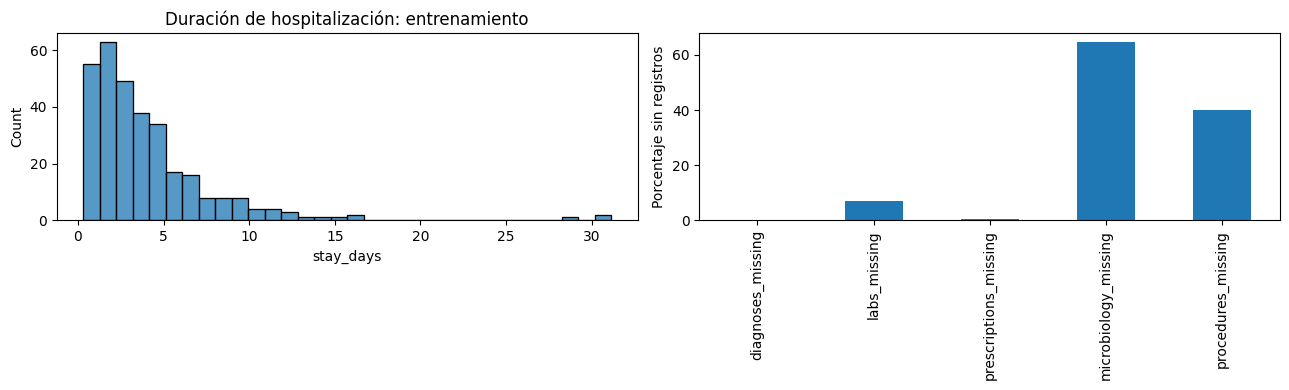

,examples
admission_type,
EW EMER.,126
OBSERVATION ADMIT,46
SURGICAL SAME DAY ADMISSION,41
URGENT,39
EU OBSERVATION,35
DIRECT OBSERVATION,11
DIRECT EMER.,10
ELECTIVE,4
AMBULATORY OBSERVATION,3


,examples
gender,
F,172
M,143


In [20]:
flow = pd.DataFrame([
    ("Notas leídas", raw_note_count), ("Admisiones limpias", clean_note_count),
    ("Notas únicas", len(source_notes)),
    ("Referencias válidas", int(source_notes["annotation_status"].isin(VALID_ANNOTATIONS).sum())),
    ("Referencias BHC únicas", len(notes_selected)), ("Pares clínicos únicos", len(pairs)),
    ("Entrenamiento seleccionado", len(train)), ("Validación", len(val)), ("Prueba", len(test)),
], columns = ["stage", "examples"])
flow.to_csv(eda_path / "FlujoDatos.csv", index = False)
display(flow)
display(pairs.groupby("split").agg(notes = ("note_id", "size"), patients = ("subject_id", "nunique")))

clinical_features = train[["note_id", "subject_id", "hadm_id", "admission_type", "gender"]].copy()
clinical_features["stay_days"] = (
    pd.to_datetime(train["dischtime"]) - pd.to_datetime(train["admittime"])
).dt.total_seconds() / 86400
for column in ["diagnoses", "labs", "prescriptions", "microbiology", "procedures"]:
    clinical_features[column + "_count"] = train[column].map(lambda value: len(clinical_records(value)))
    clinical_features[column + "_missing"] = clinical_features[column + "_count"].eq(0)
clinical_features["labs_omitted"] = train.apply(
    lambda row: clinical_compact_labs(row["labs"], clinical_parse_time(row["dischtime"]))[1], axis = 1,
)
clinical_features["medications_omitted"] = train.apply(
    lambda row: clinical_compact_medications(row["prescriptions"], clinical_parse_time(row["admittime"]), clinical_parse_time(row["dischtime"]))[1], axis = 1,
)
clinical_features["microbiology_omitted"] = train.apply(
    lambda row: clinical_compact_microbiology(row["microbiology"], clinical_parse_time(row["dischtime"]))[1], axis = 1,
)
clinical_features.to_csv(eda_path / "CoberturaClinicaTrain.csv", index = False)
display(clinical_features.describe(percentiles = [.05, .25, .50, .75, .90, .95, .99]).T)
display(clinical_features.filter(like = "_missing").mean().mul(100).rename("percent_empty"))
fig, axes = plt.subplots(1, 2, figsize = (13, 4))
sns.histplot(data = clinical_features, x = "stay_days", ax = axes[0])
axes[0].set_title("Duración de hospitalización: entrenamiento")
clinical_features.filter(like = "_missing").mean().mul(100).plot.bar(ax = axes[1])
axes[1].set_ylabel("Porcentaje sin registros")
plt.tight_layout()
plt.savefig(eda_path / "CoberturaClinica.png", dpi = 150)
plt.show()
for column in ["admission_type", "gender"]:
    display(clinical_features[column].fillna("missing").value_counts(dropna = False).to_frame("examples"))


# ANÁLISIS EXPLORATORIO: LONGITUD Y CONTENIDO DEL BHC


,count,mean,std,min,5%,25%,50%,75%,90%,95%,99%,max
discharge_chars,315.0,8885.517460,3090.571632,2642.000000,4490.000000,6662.500000,8499.000000,10618.500000,12871.400000,14679.000000,16928.280000,18802.000000
discharge_words,315.0,1346.415873,472.148931,413.000000,653.000000,1013.000000,1313.000000,1597.000000,1985.200000,2181.800000,2650.140000,2924.000000
bhc_chars,315.0,1778.304762,858.893869,196.000000,591.500000,1099.000000,1636.000000,2364.000000,2999.600000,3365.300000,3747.460000,3880.000000
bhc_words,315.0,276.926984,133.315288,29.000000,95.400000,174.500000,259.000000,375.000000,476.800000,520.000000,587.900000,649.000000
input_chars,315.0,5837.025397,2337.113974,602.000000,1864.200000,3881.500000,5893.000000,7901.500000,8653.400000,9056.900000,10149.000000,11060.000000
input_words,315.0,1001.295238,393.079122,91.000000,308.900000,676.000000,1021.000000,1364.000000,1465.600000,1508.300000,1623.740000,1763.000000
bhc_discharge_ratio,315.0,0.207907,0.079263,0.037755,0.091959,0.150876,0.199358,0.262496,0.310126,0.349039,0.414931,0.468456
bhc_input_ratio,315.0,0.329178,0.265901,0.056414,0.108912,0.182902,0.267170,0.380664,0.569817,0.696991,1.746728,1.960591
bhc_lines,315.0,36.971429,19.429338,4.000000,11.000000,21.500000,32.000000,51.500000,67.000000,72.000000,80.000000,86.000000
bhc_problem_markers,315.0,2.292063,3.445264,0.000000,0.000000,0.000000,0.000000,4.000000,7.000000,9.300000,13.000000,16.000000


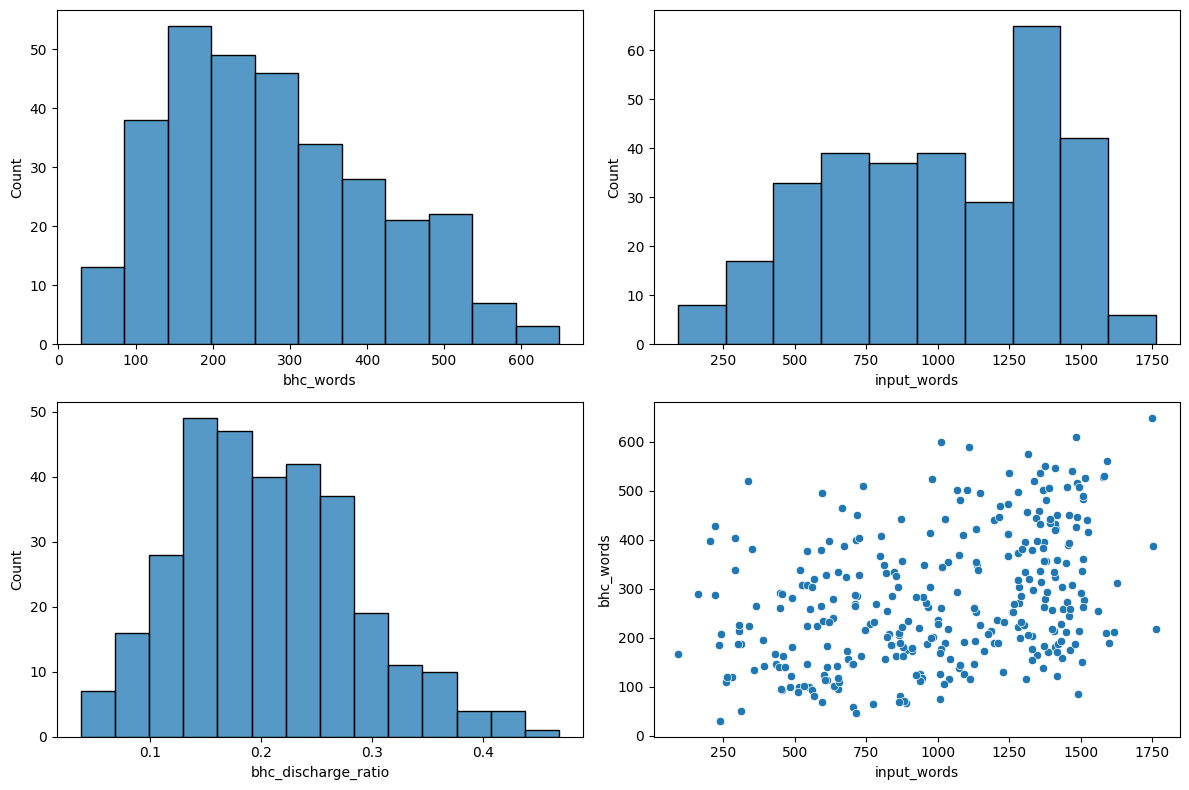

,note_id,reference_source,discharge_chars,discharge_words,bhc_chars,bhc_words,input_chars,input_words,bhc_discharge_ratio,bhc_input_ratio,bhc_lines,bhc_problem_markers,deidentification_markers,suspected_other_sections
31,11137359-DS-9,rules,11953,1817,3811,649,10978,1749,0.357182,0.371069,80,0,16,0
301,19532096-DS-9,rules,16046,2442,3808,609,8810,1482,0.249386,0.410931,67,0,15,0
167,15554509-DS-21,rules,11663,1717,3880,600,5853,1010,0.349447,0.594059,75,6,10,0
174,15831488-DS-15,rules,15756,2351,3674,590,6391,1108,0.250957,0.532491,75,3,13,0
51,12010736-DS-12,rules,11794,1791,3756,575,7566,1314,0.321050,0.437595,76,7,9,0


,note_id,reference_source,discharge_chars,discharge_words,bhc_chars,bhc_words,input_chars,input_words,bhc_discharge_ratio,bhc_input_ratio,bhc_lines,bhc_problem_markers,deidentification_markers,suspected_other_sections
272,18499543-DS-22,rules,3150,427,196,29,1441,239,0.067916,0.121339,4,0,2,0
261,18235502-DS-2,rules,2642,413,212,46,4020,714,0.111380,0.064426,4,0,1,0
120,14521957-DS-16,rules,3481,509,327,51,1955,311,0.100196,0.163987,7,0,3,0
26,10987278-DS-11,rules,4234,653,314,59,4159,702,0.090352,0.084046,5,0,2,0
243,17838879-DS-18,rules,5102,783,391,64,4572,775,0.081737,0.082581,7,0,3,0


,note_id,reference_source,discharge_chars,discharge_words,bhc_chars,bhc_words,input_chars,input_words,bhc_discharge_ratio,bhc_input_ratio,bhc_lines,bhc_problem_markers,deidentification_markers,suspected_other_sections


,word,frequency
0,patient,1427
1,pain,498
2,discharge,467
3,home,383
4,stable,349
5,given,348
6,continued,299
7,follow,288
8,admission,224
9,started,202


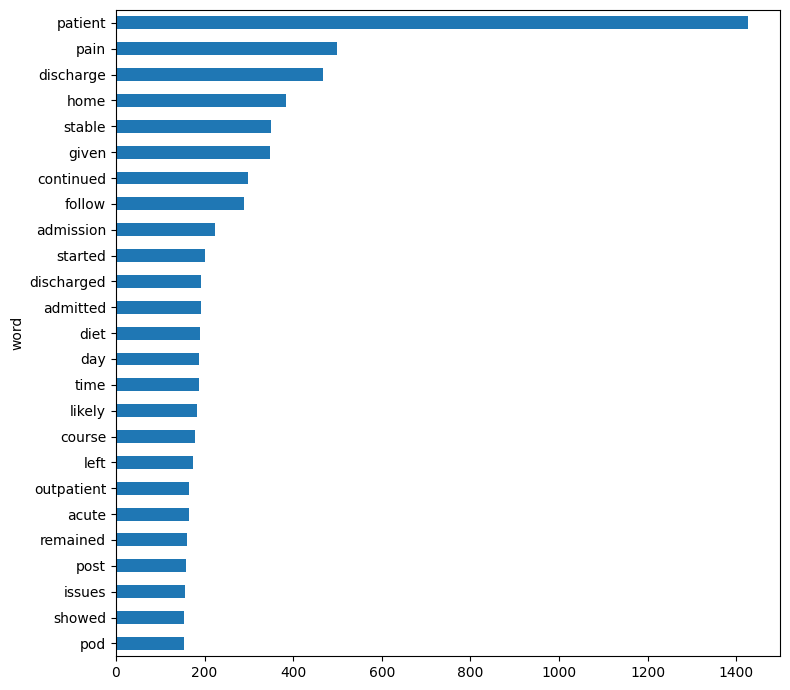

In [21]:
text_features = train[["note_id", "reference_source"]].copy()
for name, column in [("discharge", "text"), ("bhc", "bhc_text"), ("input", "clinical_input")]:
    text_features[name + "_chars"] = train[column].str.len()
    text_features[name + "_words"] = train[column].str.split().str.len()
text_features["bhc_discharge_ratio"] = text_features["bhc_words"] / text_features["discharge_words"].clip(lower = 1)
text_features["bhc_input_ratio"] = text_features["bhc_words"] / text_features["input_words"].clip(lower = 1)
text_features["bhc_lines"] = train["bhc_text"].map(lambda text: len(text.splitlines()))
text_features["bhc_problem_markers"] = train["bhc_text"].map(lambda text: len(re.findall(r"(?m)^\s*#", text)))
text_features["deidentification_markers"] = train["bhc_text"].str.count(r"___|\[\*\*")
text_features["suspected_other_sections"] = train["bhc_text"].map(lambda text: len(find_headers(text)))
text_features.to_csv(eda_path / "LongitudesTextoTrain.csv", index = False)
display(text_features.describe(percentiles = [.05, .25, .50, .75, .90, .95, .99]).T)
fig, axes = plt.subplots(2, 2, figsize = (12, 8))
for column, axis in zip(["bhc_words", "input_words", "bhc_discharge_ratio"], axes.flat):
    sns.histplot(data = text_features, x = column, ax = axis)
sns.scatterplot(data = text_features, x = "input_words", y = "bhc_words", ax = axes[1, 1])
plt.tight_layout()
plt.savefig(eda_path / "LongitudesTexto.png", dpi = 150)
plt.show()
display(text_features.nlargest(REVIEW_EXAMPLES, "bhc_words"))
display(text_features.nsmallest(REVIEW_EXAMPLES, "bhc_words"))
display(text_features.loc[text_features["suspected_other_sections"].gt(0)])

word_counts = Counter(word for text in train["bhc_text"] for word in re.findall(r"[a-z]+", text.lower()) if len(word) > 2 and word not in ENGLISH_STOP_WORDS)
vocabulary = pd.DataFrame(word_counts.most_common(TOP_WORDS), columns = ["word", "frequency"])
vocabulary.to_csv(eda_path / "VocabularioTrain.csv", index = False)
display(vocabulary)
vocabulary.set_index("word")["frequency"].sort_values().plot.barh(figsize = (8, 7))
plt.tight_layout()
plt.savefig(eda_path / "VocabularioTrain.png", dpi = 150)
plt.show()
# Frecuencias descriptivas: no se interpretan como diagnósticos ni conceptos normalizados.


# ANÁLISIS EXPLORATORIO: RELACIÓN ENTRE ENTRADA Y REFERENCIA

Se relacionan longitud del BHC, duración de estancia, volumen de eventos y omisiones
de la ficha. La coincidencia de palabras es una medida léxica aproximada: una palabra
compartida no confirma un hecho y los sinónimos pueden reducir la coincidencia.


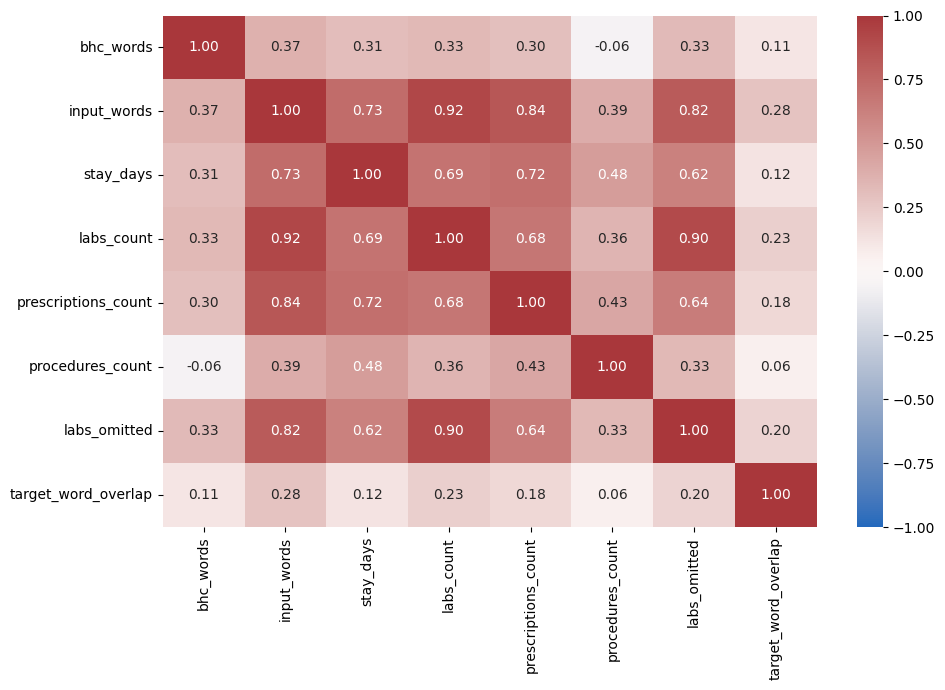

,note_id,target_word_overlap,bhc_words,input_words
223,17267579-DS-2,0.020000,93,457
111,14167153-DS-13,0.023669,398,203
260,18225977-DS-7,0.028571,116,1038
261,18235502-DS-2,0.047619,46,714
250,18044039-DS-15,0.047945,428,222


In [22]:
relationship_features = text_features.merge(clinical_features, on = "note_id", validate = "one_to_one")
lexical_rows = []
for row in train.to_dict("records"):
    source_words = set(re.findall(r"[a-z]+", row["clinical_input"].lower())) - ENGLISH_STOP_WORDS
    target_words = set(re.findall(r"[a-z]+", row["bhc_text"].lower())) - ENGLISH_STOP_WORDS
    lexical_rows.append({"note_id": row["note_id"], "target_word_overlap": len(source_words & target_words) / max(1, len(target_words))})
relationship_features = relationship_features.merge(pd.DataFrame(lexical_rows), on = "note_id", validate = "one_to_one")
relationship_features.to_csv(eda_path / "RelacionEntradaBHCTrain.csv", index = False)
correlation_columns = ["bhc_words", "input_words", "stay_days", "labs_count", "prescriptions_count", "procedures_count", "labs_omitted", "target_word_overlap"]
correlations = relationship_features[correlation_columns].corr(method = "spearman")
correlations.to_csv(eda_path / "CorrelacionesTrain.csv")
plt.figure(figsize = (10, 7))
sns.heatmap(correlations, annot = True, fmt = ".2f", center = 0, cmap = "vlag", vmin = -1, vmax = 1)
plt.tight_layout()
plt.savefig(eda_path / "CorrelacionesTrain.png", dpi = 150)
plt.show()
display(relationship_features[["note_id", "target_word_overlap", "bhc_words", "input_words"]].nsmallest(REVIEW_EXAMPLES, "target_word_overlap"))


# ANÁLISIS EXPLORATORIO: TOKENS Y EXCLUSIONES


,,examples
split,excluded_reason,
test,,68
train,,315
validation,,67


,examples,reduced_inputs,long_references
split,,,
test,68,6,0
train,315,55,0
validation,67,8,0


,count,mean,std,min,50%,90%,95%,99%,max
input_tokens_original,315.0,2909.831746,1169.152246,188.000000,3057.0,4240.0,4430.3,4886.24,5221.0
input_tokens_used,315.0,2862.155556,1107.241272,188.000000,3057.0,4096.0,4096.0,4096.00,4096.0
input_tokens_removed_net,315.0,47.676190,151.458903,0.000000,0.0,144.0,335.3,790.24,1125.0
input_retention_ratio,315.0,0.989637,0.031454,0.784524,1.0,1.0,1.0,1.00,1.0
reference_tokens,315.0,470.911111,241.950115,48.000000,432.0,856.0,931.9,969.86,1020.0


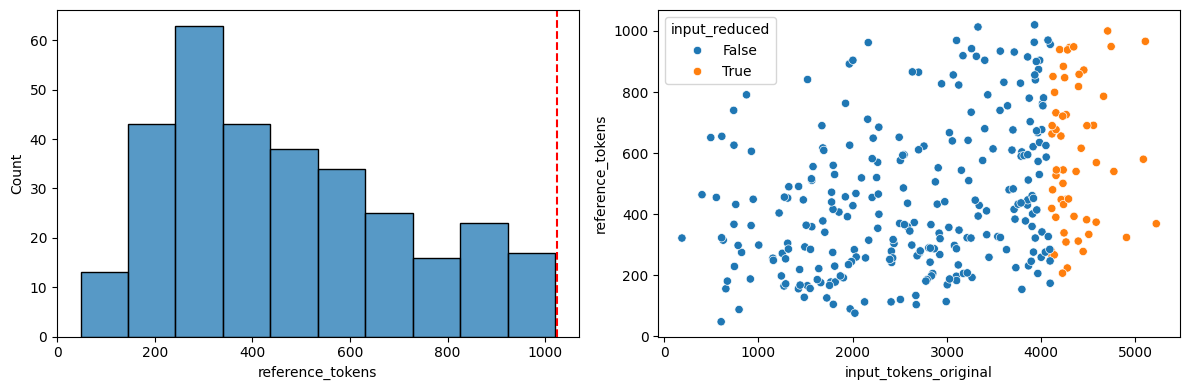

,examples,median_stay_days,median_labs,median_bhc_tokens
accepted,,,,
True,315,2.9875,68.0,432.0


,note_id,clinical_input,reference
0,10011398-DS-9,PATIENT AND ADMISSION\n- Age at deidentified a...,On ___ Mr. ___ underwent a coronary artery byp...
1,10017492-DS-10,PATIENT AND ADMISSION - Age at deidentified an...,___ with PMH significant for prior left thalam...
2,10058697-DS-19,PATIENT AND ADMISSION\n- Age at deidentified a...,The patient presented to the emergency departm...
3,10090787-DS-7,PATIENT AND ADMISSION\n- Age at deidentified a...,Mr. ___ is a ___ male with PMH significant for...
4,10106322-DS-23,PATIENT AND ADMISSION\n- Age at deidentified a...,1. Fatigue: Initial concern was for recurrent...


,count,mean,std,min,10%,50%,90%,95%,99%,max
input_tokens_original,315.0,2909.831746,1169.152246,188.000000,1288.400000,3057.0,4240.0,4430.3,4886.24,5221.0
input_tokens_used,315.0,2862.155556,1107.241272,188.000000,1288.400000,3057.0,4096.0,4096.0,4096.00,4096.0
input_tokens_removed_net,315.0,47.676190,151.458903,0.000000,0.000000,0.0,144.0,335.3,790.24,1125.0
input_retention_ratio,315.0,0.989637,0.031454,0.784524,0.966038,1.0,1.0,1.0,1.00,1.0


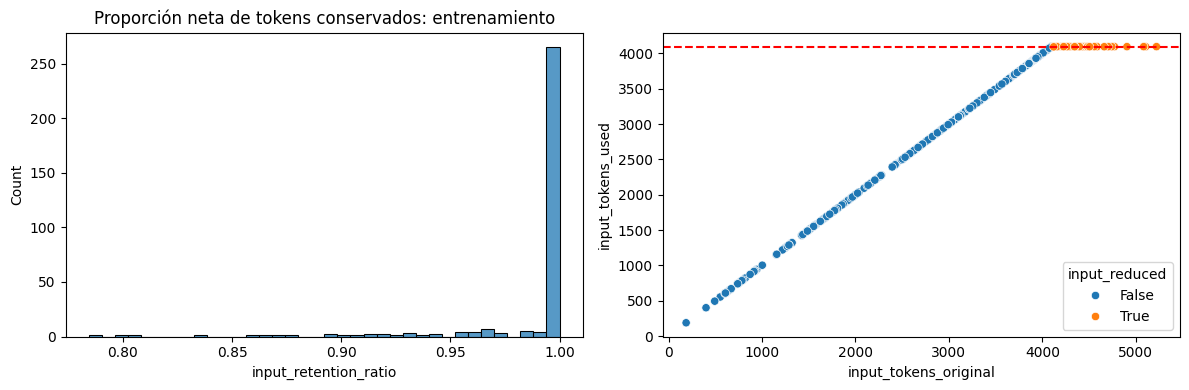

,split,accepted_examples
0,train,315
1,validation,67
2,test,68


La cohorte y los pares están guardados. La siguiente sección define el entrenamiento; hasta aquí no se han cargado pesos.


In [23]:
train_records, train_metadata, train_audit = prepare_records(train, "train")
val_records, val_metadata, val_audit = prepare_records(val, "validation")
test_records, test_metadata, test_audit = prepare_records(test, "test", enforce_budget = False)
token_audit = pd.concat([train_audit, val_audit, test_audit], ignore_index = True)
token_audit.to_csv(eda_path / "AuditoriaTokens.csv", index = False)
display(token_audit.groupby(["split", "excluded_reason"]).size().to_frame("examples"))
display(token_audit.groupby("split").agg(examples = ("note_id", "size"),
    reduced_inputs = ("input_reduced", "sum"), long_references = ("reference_exceeds_output_budget", "sum")))

display(train_audit.describe(percentiles = [.5, .9, .95, .99]).T)
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
sns.histplot(data = train_audit, x = "reference_tokens", ax = axes[0])
axes[0].axvline(MAX_TARGET_LENGTH, color = "red", linestyle = "--")
sns.scatterplot(data = train_audit, x = "input_tokens_original", y = "reference_tokens", hue = "input_reduced", ax = axes[1])
plt.tight_layout()
plt.savefig(eda_path / "TokensTrain.png", dpi = 150)
plt.show()
accepted_ids = set(train_metadata["note_id"])
bias_audit = train_audit.assign(accepted = train_audit["note_id"].isin(accepted_ids)).merge(
    clinical_features, on = "note_id", validate = "one_to_one",
)
display(bias_audit.groupby("accepted").agg(examples = ("note_id", "size"),
    median_stay_days = ("stay_days", "median"), median_labs = ("labs_count", "median"),
    median_bhc_tokens = ("reference_tokens", "median")))
bias_audit.to_csv(eda_path / "SesgoExclusionTrain.csv", index = False)

for name, records in [("train", train_records), ("validation", val_records), ("test", test_records)]:
    with (output_path / f"{name}.jsonl").open("w", encoding = "utf-8") as file:
        for record in records:
            file.write(json.dumps(record, ensure_ascii = False) + "\n")
display(train_metadata[["note_id", "clinical_input", "reference"]].head(REVIEW_EXAMPLES))

display(train_audit[["input_tokens_original", "input_tokens_used", "input_tokens_removed_net", "input_retention_ratio"]].describe(percentiles = [.1, .5, .9, .95, .99]).T)
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
sns.histplot(data = train_audit, x = "input_retention_ratio", ax = axes[0])
axes[0].set_title("Proporción neta de tokens conservados: entrenamiento")
sns.scatterplot(data = train_audit, x = "input_tokens_original", y = "input_tokens_used", hue = "input_reduced", ax = axes[1])
axes[1].axhline(MAX_INPUT_LENGTH, color = "red", linestyle = "--")
plt.tight_layout()
plt.savefig(eda_path / "ReduccionEncoderTrain.png", dpi = 150)
plt.show()

prepared_summary = pd.DataFrame({"split": ["train", "validation", "test"],
    "accepted_examples": [len(train_records), len(val_records), len(test_records)]})
display(prepared_summary)
prepared_summary.to_csv(output_path / "ResumenPares.csv", index = False)
print("La cohorte y los pares están guardados. La siguiente sección define el entrenamiento; hasta aquí no se han cargado pesos.")


In [34]:
eda_examples = train_metadata.merge(
    train_audit[[
        "note_id",
        "input_tokens_original",
        "input_tokens_used",
        "reference_tokens",
        "input_reduced",
    ]],
    on = "note_id",
    how = "inner",
    validate = "one_to_one",
)

eda_examples = eda_examples.sample(
    n = min(N_EDA_EXAMPLES, len(eda_examples)),
    random_state = SEED,
)

for number, row in enumerate(
    eda_examples.to_dict("records"), start = 1,
):
    print(
        f"EJEMPLO {number} | Nota: {row['note_id']} "
        f"| Admisión: {row['hadm_id']}"
    )

    print(
        f"Tokens de entrada: {row['input_tokens_original']} originales / "
        f"{row['input_tokens_used']} utilizados "
        f"| BHC: {row['reference_tokens']}"
    )

    print("Entrada reducida:", "Sí" if row["input_reduced"] else "No")
    print("Origen de referencia:", row["reference_source"])

    print("\nENTRADA QUE RECIBE EL ENCODER:\n")
    print(row["clinical_input"])

    print("\nBHC DE REFERENCIA:\n")
    print(row["reference"])

    print("\n" + "=" * 100 + "\n")

EJEMPLO 1 | Nota: 16814186-DS-18 | Admisión: 20599352
Tokens de entrada: 4555 originales / 4096 utilizados | BHC: 691
Entrada reducida: Sí
Origen de referencia: rules

ENTRADA QUE RECIBE EL ENCODER:

PATIENT AND ADMISSION - Age at deidentified anchor year: 83 years - Sex: F - Admission type: SURGICAL SAME DAY ADMISSION - Admission source: PHYSICIAN REFERRAL - Discharge destination: REHAB - Length of stay: 344 hours DIAGNOSES - ICD-10 I350 — Nonrheumatic aortic (valve) stenosis - ICD-10 I63423 — Cerebral infarction due to embolism of bilateral anterior cerebral arteries - ICD-10 J939 — Pneumothorax, unspecified - ICD-10 D62 — Acute posthemorrhagic anemia - ICD-10 I728 — Aneurysm of other specified arteries - ICD-10 E785 — Hyperlipidemia, unspecified - ICD-10 I10 — Essential (primary) hypertension - ICD-10 K219 — Gastro-esophageal reflux disease without esophagitis - ICD-10 I4891 — Unspecified atrial fibrillation - ICD-10 R6889 — Other general symptoms and signs PROCEDURES - ICD-10 02RF0

# DEFINICIÓN DEL MODELO Y ENTRENAMIENTO

Se ajustan lospesos de LongT5 con Seq2SeqTrainer y AdamW. La búsqueda elige la menor pérdida de validación registrada por época. Se conserva una métrica JSON por experimento completado y se reconstruye el CSV desde esos JSON si hace falta. Solo el entrenamiento final guarda pesos y checkpoints por época. No se borran archivos de corridas anteriores.

Todo se mantiene para en caso de que el entorno se detenga abruptamente, la nube de drive mantenga guardado todo el proceso realizado.

In [24]:
def clear_gpu() -> None:
    """No recibe argumentos. Libera objetos y caché CUDA; retorna None."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_base(model_route: str = MODEL_ID, for_training: bool = False) -> PreTrainedModel:
    """
    Recibe model_route (str), identificador base o carpeta de un modelo guardado,
    y for_training (bool), que desactiva la caché para gradient checkpointing.
    Retorna el modelo encoder–decoder con pesos FP32; Trainer gestiona precisión mixta.
    """
    model = AutoModelForSeq2SeqLM.from_pretrained(model_route)
    model.config.use_cache = not for_training
    return model


def get_training_settings(
    learning_rate: float, weight_decay: float, num_train_epochs: int,
    batch_size: int, warmup_ratio: float, keep_model: bool,
) -> dict:
    """
    Recibe los cinco hiperparámetros de una corrida y keep_model (bool).
    Retorna dict con la configuración completa utilizada para verificar su firma.
    """
    return {"model": MODEL_ID, "architecture": "encoder_decoder", "seed": SEED,
        "lr": learning_rate, "epochs": num_train_epochs, "batch_size": batch_size,
        "gradient_accumulation": GRADIENT_ACCUMULATION_STEPS,
        "max_input_length": MAX_INPUT_LENGTH, "max_target_length": MAX_TARGET_LENGTH,
        "max_new_tokens": MAX_NEW_TOKENS, "warmup_ratio": warmup_ratio,
        "weight_decay": weight_decay, "optimizer": "adamw_torch", "scheduler": "cosine",
        "keep_model": keep_model,
        "num_beams": NUM_BEAMS, "no_repeat_ngram_size": NO_REPEAT_NGRAM_SIZE,
        "length_penalty": LENGTH_PENALTY,
        "versions": package_versions, "gpu_count": torch.cuda.device_count(),
        "precision": training_precision}


def recover_grid_results(
    grid_rows: list[dict], records: list[dict], validation_records: list[dict],
    grid_path: Path, grid_signature: str,
) -> list[dict]:
    """
    Recibe filas de grilla, pares de búsqueda, validación, carpeta y firma de grilla.
    Retorna métricas completas recuperadas de Resultado.json con firma verificada.
    No carga modelos, no entrena y no elimina archivos. Omite JSON incompletos.
    """
    recovered = []
    for row in grid_rows:
        result_path = grid_path / f"experimento_{int(row['experiment_id'])}" / "Resultado.json"
        if not result_path.is_file():
            continue
        try:
            result = json.loads(result_path.read_text(encoding = "utf-8"))
            params = {"learning_rate": float(row["learning_rate"]), "weight_decay": float(row["weight_decay"]),
                "num_train_epochs": int(row["num_train_epochs"]), "batch_size": int(row["batch_size"]),
                "warmup_ratio": float(row["warmup_ratio"])}
            settings = get_training_settings(**params, keep_model = False)
            expected = sha256(json.dumps({"settings": settings, "train": records,
                "validation": validation_records}, sort_keys = True).encode()).hexdigest()
            if result["signature"] != expected or not np.isfinite(result["eval_loss"]):
                print("No se reutiliza un resultado con firma distinta o pérdida no finita:", result_path)
                continue
            recovered.append({"experiment_id": int(row["experiment_id"]), "grid_signature": grid_signature,
                **params, "status": "completed", "eval_loss": float(result["eval_loss"]), "error": ""})
        except (ValueError, KeyError, TypeError) as error:
            print("Resultado incompleto; se conserva para revisión:", result_path, type(error).__name__)
    return recovered


def train_generator(
    records: list[dict], validation_records: list[dict], learning_rate: float, run_path: Path,
    weight_decay: float = WEIGHT_DECAY, num_train_epochs: int = NUM_TRAIN_EPOCHS,
    batch_size: int = BATCH_SIZE, warmup_ratio: float = WARMUP_RATIO,
    keep_model: bool = True,
) -> dict:
    """
    Recibe records y validation_records (list[dict]) con clinical_input y bhc_text,
    learning_rate (float), run_path (Path), weight_decay (float), num_train_epochs
    (int), batch_size (int) y warmup_ratio (float), la configuración de la corrida.
    keep_model (bool) conserva el modelo y checkpoints; False desactiva por completo
    el guardado de pesos durante búsqueda y conserva solo métricas al completar.
    Retorna dict con hiperparámetros, pérdida, firma y ruta del modelo si se conservó.
    Reutiliza corridas completadas o retoma el último checkpoint compatible.
    """
    if not torch.cuda.is_available():
        raise RuntimeError("Activa una GPU antes de iniciar el entrenamiento.")
    if learning_rate <= 0 or weight_decay < 0 or not 0 <= warmup_ratio <= 1:
        raise ValueError("Revisa learning_rate, weight_decay y warmup_ratio.")
    if not isinstance(batch_size, (int, np.integer)) or not isinstance(num_train_epochs, (int, np.integer)):
        raise ValueError("batch_size y num_train_epochs deben ser enteros.")
    if batch_size < 1 or num_train_epochs < 1:
        raise ValueError("batch_size y num_train_epochs deben ser positivos.")
    settings = get_training_settings(learning_rate, weight_decay, num_train_epochs, batch_size, warmup_ratio, keep_model)
    fingerprint = sha256(json.dumps({"settings": settings, "train": records,
        "validation": validation_records}, sort_keys = True).encode()).hexdigest()
    run_path.mkdir(parents = True, exist_ok = True)
    signature_path = run_path / "Firma.json"
    if signature_path.exists() and json.loads(signature_path.read_text())["signature"] != fingerprint:
        raise ValueError("La carpeta contiene otra corrida. Usa otra OUTPUT_ROUTE.")
    signature_path.write_text(json.dumps({"signature": fingerprint, "settings": settings}, indent = 2), encoding = "utf-8")
    result_path = run_path / "Resultado.json"
    if result_path.exists():
        saved = json.loads(result_path.read_text())
        if keep_model:
            saved_path = Path(saved["model_path"])
            if not (saved_path / "config.json").exists() or not any((saved_path / name).exists() for name in ["model.safetensors", "pytorch_model.bin"]):
                raise FileNotFoundError("Faltan archivos del modelo completo guardado.")
        print("Corrida completada; se reutiliza:", run_path.name)
        return saved
    free_gb = shutil.disk_usage(DISK_CHECK_ROUTE).free / (1024 ** 3)
    if free_gb < MIN_FREE_DISK_GB:
        raise OSError(f"Quedan {free_gb:.2f} GiB libres en {DISK_CHECK_ROUTE}. Rescata los resultados y libera espacio antes de entrenar.")
    model, trainer = None, None
    checkpoint_path = run_path / "checkpoints"
    set_seed(SEED)
    try:
        model = load_base(for_training = True)
        args = Seq2SeqTrainingArguments(
            output_dir = str(run_path / "checkpoints"),
            num_train_epochs = num_train_epochs, learning_rate = learning_rate,
            per_device_train_batch_size = batch_size, per_device_eval_batch_size = 1,
            gradient_accumulation_steps = GRADIENT_ACCUMULATION_STEPS,
            gradient_checkpointing = True, gradient_checkpointing_kwargs = {"use_reentrant": False},
            optim = "adamw_torch", eval_strategy = "epoch",
            save_strategy = "epoch" if keep_model else "no",
            save_total_limit = 1, load_best_model_at_end = keep_model,
            metric_for_best_model = "eval_loss", greater_is_better = False,
            logging_strategy = "epoch", warmup_steps = 0, weight_decay = weight_decay,
            lr_scheduler_type = "cosine", fp16 = False, bf16 = use_bf16,
            seed = SEED, data_seed = SEED, report_to = "none",
            predict_with_generate = False, prediction_loss_only = True,
            dataloader_num_workers = 0,
        )
        trainer = Seq2SeqTrainer(model = model, args = args,
            train_dataset = prepare_dataset(records), eval_dataset = prepare_dataset(validation_records),
            processing_class = tokenizer,
            data_collator = DataCollatorForSeq2Seq(tokenizer = tokenizer, model = model, label_pad_token_id = -100))
        steps_per_epoch = max(1, int(np.ceil(len(trainer.get_train_dataloader()) / GRADIENT_ACCUMULATION_STEPS)))
        trainer.args.warmup_steps = int(np.ceil(steps_per_epoch * num_train_epochs * warmup_ratio))
        probe = next(iter(trainer.get_train_dataloader()))
        del probe
        checkpoint_path = run_path / "checkpoints"
        checkpoint = get_last_checkpoint(str(checkpoint_path)) if keep_model and checkpoint_path.exists() else None
        trainer.train(resume_from_checkpoint = checkpoint)
        metrics = trainer.evaluate()
        history = [row for row in getattr(getattr(trainer, "state", None), "log_history", [])
            if "eval_loss" in row and np.isfinite(row["eval_loss"])]
        best_evaluation = min(history, key = lambda row: row["eval_loss"]) if history else metrics
        selection_loss = metrics["eval_loss"] if keep_model else best_evaluation["eval_loss"]
        model_path = run_path / "modelo" if keep_model else None
        if keep_model:
            trainer.save_model(str(model_path))
            tokenizer.save_pretrained(str(model_path))
        result = {"learning_rate": float(learning_rate), "eval_loss": float(selection_loss),
            "evaluated_model_loss": float(metrics["eval_loss"]), "best_epoch": best_evaluation.get("epoch"),
            "weight_decay": float(weight_decay), "num_train_epochs": int(num_train_epochs),
            "batch_size": int(batch_size), "warmup_ratio": float(warmup_ratio),
            "model_path": str(model_path) if keep_model else None, "signature": fingerprint,
            "train_examples": len(records), "validation_examples": len(validation_records)}
        temporary = run_path / "Resultado.tmp.json"
        temporary.write_text(json.dumps(result, indent = 2), encoding = "utf-8")
        temporary.replace(result_path)
        return result
    finally:
        del trainer, model
        clear_gpu()


# BÚSQUEDA DE HIPERPARÁMETROS

Se comparan cinco hiperparámetros con una muestra fija: 4 × 3 × 2 × 2 × 2 = 96
combinaciones. La acumulación de gradientes permanece fija, por lo que el batch size
también cambia el lote efectivo. Se elige la menor pérdida de validación.

MAX_NEW_EXPERIMENTS=None ejecuta todas las pendientes; un entero permite trabajar
por bloques. La búsqueda no guarda pesos ni checkpoints: registra métricas en JSON
por experimento y actualiza el CSV tras cada corrida. Una búsqueda interrumpida se
repite desde la base; las completadas se reutilizan. Solo el entrenamiento final
conserva pesos y checkpoints. No se eliminan automáticamente archivos anteriores.


In [25]:
required_parameters = {"learning_rate", "weight_decay", "num_train_epochs", "batch_size", "warmup_ratio", "keep_model"}

search_indices = np.random.default_rng(SEED).choice(
    len(train_records), size = min(N_SEARCH_ADMISSIONS, len(train_records)), replace = False,
)
search_records = [train_records[int(i)] for i in sorted(search_indices)]
grid_columns = ["learning_rate", "weight_decay", "num_train_epochs", "batch_size", "warmup_ratio"]
grid = pd.DataFrame(list(product(LEARNING_RATES, WEIGHT_DECAYS, TRAIN_EPOCHS, BATCH_SIZES, WARMUP_RATIOS)), columns = grid_columns)
grid.insert(0, "experiment_id", np.arange(1, len(grid) + 1))
display(grid.head(15))
print("Combinaciones:", len(grid))
grid_path = output_path / "grilla"
grid_path.mkdir(parents = True, exist_ok = True)
grid_settings = {
    "model": MODEL_ID, "seed": SEED, "max_input_length": MAX_INPUT_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH, "max_new_tokens": MAX_NEW_TOKENS,
    "accumulation": GRADIENT_ACCUMULATION_STEPS, "num_beams": NUM_BEAMS,
    "no_repeat_ngram_size": NO_REPEAT_NGRAM_SIZE, "length_penalty": LENGTH_PENALTY,
    "versions": package_versions, "gpu_count": torch.cuda.device_count(),
    "precision": training_precision,
    "grid": grid[grid_columns].to_dict("records"),
}
grid_signature = sha256(json.dumps({"settings": grid_settings, "train": search_records,
    "validation": val_records}, sort_keys = True).encode()).hexdigest()
grid_results_path = grid_path / "Experimentos.csv"
if grid_results_path.exists():
    try:
        saved = pd.read_csv(grid_results_path)
    except (pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeDecodeError):
        print("Se conserva el CSV ilegible y se reconstruye otro desde los JSON.")
        grid_results_path = grid_path / "Experimentos_Recuperados.csv"
        experiments = []
    else:
        experiments = saved.to_dict("records")
else:
    experiments = []
recovered_results = recover_grid_results(grid.to_dict("records"), search_records, val_records, grid_path, grid_signature)
experiments = pd.DataFrame(experiments + recovered_results).drop_duplicates("experiment_id", keep = "last").to_dict("records") if experiments or recovered_results else []
print("Resultados completos encontrados en JSON:", len(recovered_results))
if experiments:
    temporary_results_path = grid_path / "Experimentos.tmp.csv"
    pd.DataFrame(experiments).to_csv(temporary_results_path, index = False)
    temporary_results_path.replace(grid_results_path)
elif not grid_results_path.exists():
    pd.DataFrame(columns = ["experiment_id", "grid_signature", *grid_columns, "status", "eval_loss", "error"]).to_csv(grid_results_path, index = False)

grid.to_csv(grid_path / "GrillaCompleta.csv", index = False)
(grid_path / "Configuracion.json").write_text(json.dumps({"signature": grid_signature, "settings": grid_settings}, indent = 2), encoding = "utf-8")
completed_ids = {int(row["experiment_id"]) for row in experiments if row["status"] == "completed"}
pending = [row for row in grid.to_dict("records") if row["experiment_id"] not in completed_ids]
if MAX_NEW_EXPERIMENTS is not None:
    pending = pending[:MAX_NEW_EXPERIMENTS]
print("Completadas:", len(completed_ids), "Pendientes a ejecutar:", len(pending))
for parameters in pending:
    experiment_id = int(parameters["experiment_id"])
    trial_params = {
        "learning_rate": float(parameters["learning_rate"]), "weight_decay": float(parameters["weight_decay"]),
        "num_train_epochs": int(parameters["num_train_epochs"]), "batch_size": int(parameters["batch_size"]),
        "warmup_ratio": float(parameters["warmup_ratio"]),
    }
    record = {"experiment_id": experiment_id, "grid_signature": grid_signature, **trial_params}
    print(f"Experimento {experiment_id}/{len(grid)}:", trial_params)
    try:
        result = train_generator(search_records, val_records, run_path = grid_path / f"experimento_{experiment_id}",
            keep_model = False, **trial_params)
        record.update({"status": "completed", "eval_loss": result["eval_loss"], "error": ""})
    except (torch.cuda.OutOfMemoryError, FloatingPointError) as error:
        record.update({"status": "failed", "error": str(error)[:1000]})
        print("Corrida no completada:", type(error).__name__)
    experiments.append(record)
    temporary_results_path = grid_path / "Experimentos.tmp.csv"
    pd.DataFrame(experiments).drop_duplicates("experiment_id", keep = "last").to_csv(temporary_results_path, index = False)
    temporary_results_path.replace(grid_results_path)
attempts_df = pd.DataFrame(experiments).drop_duplicates("experiment_id", keep = "last")
experiments_df = attempts_df.loc[attempts_df["status"].eq("completed")].sort_values("eval_loss", kind = "mergesort").reset_index(drop = True)
best = experiments_df.iloc[0]
best_params = {"learning_rate": float(best["learning_rate"]), "weight_decay": float(best["weight_decay"]),
    "num_train_epochs": int(best["num_train_epochs"]), "batch_size": int(best["batch_size"]),
    "warmup_ratio": float(best["warmup_ratio"])}
best_learning_rate = best_params["learning_rate"]
display(experiments_df)
print("Mejores hiperparámetros:", best_params)
print(f"Corridas completadas: {len(experiments_df)}/{len(grid)}")
if len(experiments_df) < len(grid):
    print("Búsqueda parcial: el ganador corresponde solo a las corridas completadas.")


,experiment_id,learning_rate,weight_decay,num_train_epochs,batch_size,warmup_ratio
0,1,0.00001,0.00,1,1,0.03
1,2,0.00001,0.00,1,1,0.10
2,3,0.00001,0.00,1,2,0.03
3,4,0.00001,0.00,1,2,0.10
4,5,0.00001,0.00,2,1,0.03
5,6,0.00001,0.00,2,1,0.10
6,7,0.00001,0.00,2,2,0.03
7,8,0.00001,0.00,2,2,0.10
8,9,0.00001,0.01,1,1,0.03
9,10,0.00001,0.01,1,1,0.10


Combinaciones: 96
Resultados completos encontrados en JSON: 91
Completadas: 91 Pendientes a ejecutar: 5
Experimento 92/96: {'learning_rate': 5e-05, 'weight_decay': 0.1, 'num_train_epochs': 1, 'batch_size': 2, 'warmup_ratio': 0.1}


pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

... (16 outputs left out)

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,5.061900,3.382053
2,4.828100,3.355968


,experiment_id,grid_signature,learning_rate,weight_decay,num_train_epochs,batch_size,warmup_ratio,status,eval_loss,error
0,85,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00005,0.01,2,1,0.03,completed,3.288424,
1,93,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00005,0.10,2,1,0.03,completed,3.290893,
2,86,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00005,0.01,2,1,0.10,completed,3.298414,
3,78,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00005,0.00,2,1,0.10,completed,3.299755,
4,77,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00005,0.00,2,1,0.03,completed,3.303444,
...,...,...,...,...,...,...,...,...,...,...
91,60,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00003,0.01,1,2,0.10,completed,3.488837,
92,31,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00002,0.00,2,2,0.03,completed,3.490724,
93,32,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00002,0.00,2,2,0.10,completed,3.490724,
94,47,90dc87c0483f498ad23c029fa9ed5e76209da9d4d64ca4...,0.00002,0.10,2,2,0.03,completed,3.496105,


Mejores hiperparámetros: {'learning_rate': 5e-05, 'weight_decay': 0.01, 'num_train_epochs': 2, 'batch_size': 1, 'warmup_ratio': 0.03}
Corridas completadas: 96/96


# ENTRENAMIENTO FINAL Y GUARDADO


## Constantes necesarias

In [27]:
FINAL_TRAIN_SIZE = 1000 # Tamaño final de la cohorte
N_EDA_EXAMPLES = 3

## Ampliación Cohorte

In [26]:
def value_hash(value: object) -> str:
    """
    Recibe un valor serializable y retorna su hash para detectar duplicados.
    """
    return sha256(
        json.dumps(value, sort_keys = True, ensure_ascii = False).encode()
    ).hexdigest()


def enlarge_training(
    target_size: int,
    clinical_query: str,
) -> tuple[list[dict], pd.DataFrame]:
    """
    Recibe el tamaño final de entrenamiento y la consulta clínica del cuaderno.

    Retorna los pares ampliados y una tabla de los ejemplos nuevos.
    Conserva los conjuntos originales y guarda el avance en otra carpeta.
    """
    if not isinstance(target_size, int) or target_size < 1:
        raise ValueError("target_size debe ser un entero positivo.")

    if target_size <= len(train_records):
        return list(train_records), pd.DataFrame()

    if COHORT_ROUTE:
        raise ValueError(
            "Este bloque requiere COHORT_ROUTE vacío; "
            "el filtro externo debe ampliarse por separado."
        )

    if "@selected_ids" not in clinical_query:
        raise ValueError(
            "Debes pasar query, la consulta clínica con @selected_ids."
        )

    extra_path = output_path / f"ampliacion_train_{target_size}"
    extra_path.mkdir(parents = True, exist_ok = True)
    cache_path = extra_path / "EstadoAmpliacion.json"

    settings = {
        "model": MODEL_ID,
        "tokenizer": tokenizer.name_or_path,
        "versions": package_versions,
        "target_size": target_size,
        "seed": SEED,
        "input_length": MAX_INPUT_LENGTH,
        "target_length": MAX_TARGET_LENGTH,
        "bhc_length": MAX_BHC_TOKENS,
        "min_chars": MIN_BHC_CHARS,
        "headers": HEADER_PATTERN.pattern,
        "headers_alone": HEADER_ALONE_PATTERN.pattern,
        "clinical_limits": [
            MAX_LAB_EVENTS,
            MAX_MEDICATION_EVENTS,
            MAX_MICROBIOLOGY_EVENTS,
        ],
        "clinical_query": clinical_query,
        "cohort_ids": cohort[
            ["note_id", "subject_id", "hadm_id"]
        ].to_dict("records"),
        "train": train_records,
        "validation": val_records,
        "test": test_records,
    }

    signature_value = value_hash(settings)

    if cache_path.exists():
        state = json.loads(cache_path.read_text(encoding = "utf-8"))

        if state["signature"] != signature_value:
            raise ValueError(
                "La ampliación guardada corresponde a otros datos "
                "o configuración."
            )
    else:
        state = {
            "signature": signature_value,
            "job_id": selection_state["job_id"],
            "location": selection_state["location"],
            "processed_rows": selection_state["processed_rows"],
            "examples": [],
        }

        save_selection_state(state, cache_path)

    # Ningún paciente original puede incorporarse como un ejemplo nuevo.
    patients = set(cohort["subject_id"].astype(int))

    references = pd.concat([
        cohort["bhc_text"],
        source_notes["bhc_text"],
    ]).dropna().astype(str)

    reference_hashes = {
        value_hash(" ".join(text.lower().split()))
        for text in references
    }

    reference_tokens = {
        value_hash(tokenizer(
            text_target = text,
            truncation = False,
            verbose = False,
        )["input_ids"])
        for text in references
    }

    full_inputs = {
        value_hash(" ".join(text.lower().split()))
        for text in pairs["clinical_input"]
    }

    used_inputs = {
        value_hash(input_ids(row["clinical_input"]))
        for row in train_records + val_records + test_records
    }

    def register_example(example: dict) -> bool:
        """
        Recibe un ejemplo preparado.

        Retorna False si repite paciente, BHC o entrada.
        Si es nuevo, registra sus identificadores para evitar duplicados.
        """
        patient = int(example["subject_id"])

        reference = value_hash(
            " ".join(example["bhc_text"].lower().split())
        )

        target = value_hash(tokenizer(
            text_target = example["bhc_text"],
            truncation = False,
            verbose = False,
        )["input_ids"])

        used_input = value_hash(input_ids(example["clinical_input"]))

        if (
            patient in patients
            or reference in reference_hashes
            or target in reference_tokens
            or example["full_input_hash"] in full_inputs
            or used_input in used_inputs
        ):
            return False

        patients.add(patient)
        reference_hashes.add(reference)
        reference_tokens.add(target)
        full_inputs.add(example["full_input_hash"])
        used_inputs.add(used_input)

        return True

    for example in state["examples"]:
        if not register_example(example):
            raise ValueError(
                "El respaldo contiene un ejemplo repetido respecto "
                "a los conjuntos originales."
            )

    required = target_size - len(train_records)

    if len(state["examples"]) > required:
        raise ValueError(
            "El respaldo contiene más ejemplos de los solicitados."
        )

    if len(state["examples"]) < required:
        try:
            job = client.get_job(
                state["job_id"],
                location = state["location"],
            )

            rows = job.result(
                page_size = QUERY_BATCH_SIZE,
                start_index = state["processed_rows"],
            )

        except NotFound:
            print(
                "El trabajo anterior expiró. Se inicia otra consulta "
                "y se conservan los ejemplos guardados."
            )

            job = start_cohort_query(client)

            state.update(
                job_id = job.job_id,
                location = job.location,
                processed_rows = 0,
            )

            save_selection_state(state, cache_path)
            rows = job.result(page_size = QUERY_BATCH_SIZE)

        try:
            for page in rows.pages:
                raw_rows = list(page)
                candidates = []
                page_patients = set()

                for raw in raw_rows:
                    patient = int(raw["subject_id"])

                    if patient in patients or patient in page_patients:
                        continue

                    candidate, _ = bhc_candidate(raw, tokenizer)

                    if candidate is not None:
                        candidates.append(candidate)
                        page_patients.add(patient)

                if candidates:
                    candidate_frame = pd.DataFrame(candidates)

                    ids = sorted(
                        candidate_frame["hadm_id"]
                        .astype(int)
                        .unique()
                        .tolist()
                    )

                    config = bigquery.QueryJobConfig(
                        query_parameters = [
                            bigquery.ArrayQueryParameter(
                                "selected_ids", "INT64", ids,
                            ),
                        ],
                    )

                    clinical = client.query(
                        clinical_query,
                        job_config = config,
                    ).to_dataframe(create_bqstorage_client = False)

                    if clinical["hadm_id"].duplicated().any():
                        raise ValueError(
                            "La consulta clínica devolvió admisiones repetidas."
                        )

                    batch = candidate_frame.merge(
                        clinical.rename(columns = {
                            "subject_id": "tabular_subject_id",
                        }),
                        on = "hadm_id",
                        how = "inner",
                        validate = "one_to_one",
                    )

                    if not batch.empty:
                        same_patient = (
                            batch["subject_id"].astype(int)
                            .eq(batch["tabular_subject_id"].astype(int))
                        )

                        if not same_patient.all():
                            raise ValueError(
                                "subject_id no coincide entre notas "
                                "y datos clínicos."
                            )

                        batch["clinical_input"] = batch.apply(
                            gen_build_clinical_input, axis = 1,
                        )

                        original_inputs = (
                            batch.set_index("note_id")["clinical_input"]
                            .to_dict()
                        )

                        records, metadata, audit = prepare_records(
                            batch, "train",
                        )

                        audit_by_id = (
                            audit.set_index("note_id").to_dict("index")
                        )

                        for record, info in zip(
                            records, metadata.to_dict("records"),
                        ):
                            counts = audit_by_id[info["note_id"]]

                            example = {
                                "note_id": info["note_id"],
                                "subject_id": int(info["subject_id"]),
                                "hadm_id": int(info["hadm_id"]),
                                "reference_source": info["reference_source"],
                                **record,
                                "full_input_hash": value_hash(
                                    " ".join(
                                        original_inputs[info["note_id"]]
                                        .lower().split()
                                    )
                                ),
                                "input_tokens_original": int(
                                    counts["input_tokens_original"]
                                ),
                                "input_tokens_used": int(
                                    counts["input_tokens_used"]
                                ),
                                "reference_tokens": int(
                                    counts["reference_tokens"]
                                ),
                                "input_reduced": bool(
                                    counts["input_reduced"]
                                ),
                            }

                            if register_example(example):
                                state["examples"].append(example)

                            if len(state["examples"]) >= required:
                                break

                # Confirmar el cursor después de preparar la página.
                state["processed_rows"] += len(raw_rows)
                save_selection_state(state, cache_path)

                print(
                    "Entrenamiento disponible:",
                    f"{len(train_records) + len(state['examples'])}"
                    f"/{target_size}",
                )

                if len(state["examples"]) >= required:
                    break

        finally:
            save_selection_state(state, cache_path)

    if len(state["examples"]) < required:
        raise ValueError(
            f"Solo se reunieron "
            f"{len(train_records) + len(state['examples'])} pares. "
            "El avance está guardado; todavía no se inicia el entrenamiento."
        )

    extra = pd.DataFrame(state["examples"])
    extra.to_csv(extra_path / "NuevosParesTrain.csv", index = False)

    extra_records = [
        {
            "clinical_input": row["clinical_input"],
            "bhc_text": row["bhc_text"],
        }
        for row in state["examples"]
    ]

    final_records = list(train_records) + extra_records

    with (extra_path / "train_final.jsonl").open(
        "w", encoding = "utf-8",
    ) as file:
        for record in final_records:
            file.write(json.dumps(record, ensure_ascii = False) + "\n")

    return final_records, extra

In [28]:
train_records_final, extra_train = enlarge_training(
    FINAL_TRAIN_SIZE,
    query,
)

display(pd.DataFrame([
    {"conjunto": "Muestra de grilla", "ejemplos": len(search_records)},
    {"conjunto": "Entrenamiento original", "ejemplos": len(train_records)},
    {"conjunto": "Ejemplos nuevos", "ejemplos": len(extra_train)},
    {"conjunto": "Entrenamiento final", "ejemplos": len(train_records_final)},
    {"conjunto": "Validación", "ejemplos": len(val_records)},
    {"conjunto": "Prueba", "ejemplos": len(test_records)},
]))

print("Hiperparámetros seleccionados:", best_params)

Entrenamiento disponible: 345/1000
Entrenamiento disponible: 385/1000
Entrenamiento disponible: 417/1000
Entrenamiento disponible: 449/1000
Entrenamiento disponible: 480/1000
Entrenamiento disponible: 516/1000
Entrenamiento disponible: 543/1000
Entrenamiento disponible: 566/1000
Entrenamiento disponible: 595/1000
Entrenamiento disponible: 637/1000
Entrenamiento disponible: 680/1000
Entrenamiento disponible: 718/1000
Entrenamiento disponible: 759/1000
Entrenamiento disponible: 789/1000
Entrenamiento disponible: 824/1000
Entrenamiento disponible: 856/1000
Entrenamiento disponible: 893/1000
Entrenamiento disponible: 939/1000
Entrenamiento disponible: 963/1000
Entrenamiento disponible: 995/1000
Entrenamiento disponible: 1000/1000


,conjunto,ejemplos
0,Muestra de grilla,60
1,Entrenamiento original,315
2,Ejemplos nuevos,685
3,Entrenamiento final,1000
4,Validación,67
5,Prueba,68


Hiperparámetros seleccionados: {'learning_rate': 5e-05, 'weight_decay': 0.01, 'num_train_epochs': 2, 'batch_size': 1, 'warmup_ratio': 0.03}


## Entrenamiento final

In [29]:
final_result = train_generator(train_records, val_records, run_path = output_path / "entrenamiento_final", **best_params)
model_path = Path(final_result["model_path"])
results = {"model_id": MODEL_ID, "seed": SEED, "target": "Brief Hospital Course",
    "learning_rate": best_learning_rate, "num_train_epochs": best_params["num_train_epochs"],
    "batch_size": best_params["batch_size"], "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "warmup_ratio": best_params["warmup_ratio"], "weight_decay": best_params["weight_decay"],
    "architecture": "encoder_decoder", "max_input_length": MAX_INPUT_LENGTH, "max_target_length": MAX_TARGET_LENGTH, "max_new_tokens": MAX_NEW_TOKENS, "num_beams": NUM_BEAMS, "no_repeat_ngram_size": NO_REPEAT_NGRAM_SIZE, "length_penalty": LENGTH_PENALTY,
    "train_examples": len(train_records), "validation_examples": len(val_records), "test_examples": len(test_records),
    "model_path": str(model_path), "versions": package_versions, "precision": training_precision,
    "best_hyperparameters": best_params, "grid_combinations": len(grid), "grid_attempted": len(attempts_df), "grid_completed": len(experiments_df), "final_training": final_result}
(output_path / "Resultados.json").write_text(json.dumps(results, ensure_ascii = False, indent = 2), encoding = "utf-8")


Map:   0%|          | 0/315 [00:00<?, ? examples/s]

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.326400,3.089282
2,3.911400,3.052526


1542

# EVALUACIÓN: MODELO BASE Y MODELO AJUSTADO

Se usan las mismas entradas de prueba, generación determinista y referencias BHC completas.
Se reportan ROUGE, METEOR y BLEU de corpus. Se compara por procedencia de referencia
y longitud, y se registra si la generación alcanza el límite de salida. Las métricas
de similitud no prueban factualidad ni utilidad clínica por sí solas.


In [30]:
nltk.download("wordnet", quiet = True)
nltk.download("omw-1.4", quiet = True)
rouge = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer = True)
bleu = BLEU(effective_order = True)


def evaluate_generator(model: PreTrainedModel, model_name: str) -> pd.DataFrame:
    """
    Recibe model (modelo encoder–decoder) y model_name (str), el nombre de evaluación.
    Retorna DataFrame con BHC generados, referencias completas y métricas por ejemplo.
    Decodifica la salida del decoder completa, sin retirar tokens de la entrada.
    """
    model.to(device)
    model.eval()
    model.config.use_cache = True
    predictions = []
    for row in test_metadata.to_dict("records"):
        encoded = tokenizer(row["clinical_input"], return_tensors = "pt", truncation = False).to(device)
        if encoded["input_ids"].shape[1] > MAX_INPUT_LENGTH:
            raise ValueError("Una entrada de prueba supera MAX_INPUT_LENGTH.")
        with torch.inference_mode():
            generated = model.generate(**encoded, max_new_tokens = MAX_NEW_TOKENS,
                min_new_tokens = 0, do_sample = False, num_beams = NUM_BEAMS,
                no_repeat_ngram_size = NO_REPEAT_NGRAM_SIZE, length_penalty = LENGTH_PENALTY,
                early_stopping = True, pad_token_id = tokenizer.pad_token_id,
                eos_token_id = tokenizer.eos_token_id, use_cache = True)
        generated_tokens = int(generated.shape[1] - 1)
        prediction = tokenizer.decode(generated[0], skip_special_tokens = True).strip()
        scores = rouge.score(row["reference"], prediction)
        predictions.append({**row, "model": model_name, "prediction": prediction,
            "generated_tokens": generated_tokens, "reached_output_limit": generated_tokens >= MAX_NEW_TOKENS,
            "meteor": meteor_score([row["reference"].split()], prediction.split()),
            **{name + "_f1": score.fmeasure for name, score in scores.items()}})
    return pd.DataFrame(predictions)


In [31]:
base_model = load_base()
try:
    base_predictions = evaluate_generator(base_model, "base")
finally:
    del base_model
    clear_gpu()

tuned_model = load_base(str(model_path))
try:
    tuned_predictions = evaluate_generator(tuned_model, "ajustado")
finally:
    del tuned_model
    clear_gpu()

predictions = pd.concat([base_predictions, tuned_predictions], ignore_index = True)
predictions = predictions.merge(test_audit[["note_id", "reference_tokens", "input_reduced"]], on = "note_id", validate = "many_to_one")
predictions["long_reference"] = predictions["reference_tokens"].gt(MAX_TARGET_LENGTH)
predictions.to_csv(output_path / "PrediccionesTest.csv", index = False)
metric_columns = ["rouge1_f1", "rouge2_f1", "rougeL_f1", "meteor"]
summary = predictions.groupby("model")[metric_columns].agg(["mean", "std", "count"])
display(summary)
summary.to_csv(output_path / "MetricasTest.csv")
corpus_scores = []
for name, frame in predictions.groupby("model"):
    corpus_scores.append({"model": name, "corpus_bleu": bleu.corpus_score(frame["prediction"].tolist(), [frame["reference"].tolist()]).score})
display(pd.DataFrame(corpus_scores))
pd.DataFrame(corpus_scores).to_csv(output_path / "BLEUCorpus.csv", index = False)
stratified = predictions.groupby(["model", "reference_source", "long_reference"])[metric_columns].agg(["mean", "count"])
display(stratified)
stratified.to_csv(output_path / "MetricasPorReferenciaLongitud.csv")
display(predictions.groupby("model")[["reached_output_limit", "input_reduced"]].mean())

# Bootstrap pareado por paciente para no tratar sus admisiones como independientes.
paired = predictions.pivot(index = ["subject_id", "note_id"], columns = "model", values = "rougeL_f1")
patient_deltas = (paired["ajustado"] - paired["base"]).groupby(level = "subject_id").mean().to_numpy()
bootstrap_rng = np.random.default_rng(SEED)
bootstrap_means = [bootstrap_rng.choice(patient_deltas, size = len(patient_deltas), replace = True).mean() for _ in range(BOOTSTRAP_SAMPLES)]
comparison = {"metric": "ROUGE-L F1", "aggregation": "mean difference per patient",
    "delta": float(patient_deltas.mean()), "ci_95": np.quantile(bootstrap_means, [.025, .975]).tolist(),
    "patients": len(patient_deltas), "bootstrap_samples": BOOTSTRAP_SAMPLES}
display(comparison)
results["test_comparison"] = comparison
(output_path / "Resultados.json").write_text(json.dumps(results, ensure_ascii = False, indent = 2), encoding = "utf-8")


rouge1_f1                 rouge2_f1                 rougeL_f1  \
              mean       std count      mean       std count      mean   
model                                                                    
ajustado  0.075836  0.030604    68  0.009612  0.016020    68  0.053155   
base      0.070139  0.043109    68  0.002381  0.004083    68  0.037879   

                           meteor                  
              std count      mean       std count  
model                                              
ajustado  0.02075    68  0.023294  0.012561    68  
base      0.01978    68  0.027122  0.018801    68

,model,corpus_bleu
0,ajustado,0.006396
1,base,0.158201


rouge1_f1       rouge2_f1        \
                                              mean count      mean count   
model    reference_source long_reference                                   
ajustado rules            False           0.075836    68  0.009612    68   
base     rules            False           0.070139    68  0.002381    68   

                                         rougeL_f1          meteor        
                                              mean count      mean count  
model    reference_source long_reference                                  
ajustado rules            False           0.053155    68  0.023294    68  
base     rules            False           0.037879    68  0.027122    68

,reached_output_limit,input_reduced
model,,
ajustado,0.000000,0.088235
base,0.397059,0.088235


{'metric': 'ROUGE-L F1',
 'aggregation': 'mean difference per patient',
 'delta': 0.015275576145808267,
 'ci_95': [0.009122214167898908, 0.021235859513708377],
 'patients': 68,
 'bootstrap_samples': 1000}

1810

# REVISIÓN DE INFERENCIAS


In [33]:
review_samples = predictions.loc[predictions["model"].eq("ajustado")].head(REVIEW_EXAMPLES)
for idx, row in enumerate(review_samples.to_dict("records"), 1):
    print(f"=== Ejemplo {idx} (ID Nota: {row['note_id']}) ===")
    print(f"REFERENCIA REAL (recortada):\n{row['reference'][:250]}...")
    print(f"PREDICCIÓN DEL MODELO (recortada):\n{row['prediction'][:250]}...")
    print("-" * 80 + "\n")

=== Ejemplo 1 (ID Nota: 10009203-DS-9) ===
REFERENCIA REAL (recortada):
# Colitis: Patient presented with one bloody bowel movement 
associated with crampy abdominal pain.  CT showing acute colitis 
of descending colon. Differential diagnosis includes infectious 
(bacterial, viral, parasitic), ischemic, and inflammatory....
PREDICCIÓN DEL MODELO (recortada):
He was admitted to the hospital with a history of noninfectious gastroenteritis and colitis....
--------------------------------------------------------------------------------

=== Ejemplo 2 (ID Nota: 10129882-DS-2) ===
REFERENCIA REAL (recortada):
On ___, Ms. ___ was admitted to the gynecology service 
after undergoing a total abdominal hysterectomy, right 
salpingo-oophorectomy, left salpingectomy for a symptomatic 
fibroid uterus. Please see the operative report for full 
details.

Her post-...
PREDICCIÓN DEL MODELO (recortada):
PATIENT AND ADMISSION - Age at deidentified anchor year: 43 years - Sex: F - Admission type: SURGICA

# **CONCLUSIONES**

El aumento de la cohorte favoreció en la reducción del error, aunque esto no indique necesariamente una mejora, ya que las métricas y el error miden cosas diferentes. Con una cohorte de 1000 pacientes el modelo fué capaz de mantener la estructura de la referencia y generar una estructura lógica, legible y con sentido, pero no necesariamente con una similitud con la salida esperada.

Un mejor resultado se podría esperar de un analisis mas profundo sobre los datos a utilizar, las inferencias leidas parecen mostrar que el modelo tuvo capacidad de incluir los datos que se le entregaron como entrada, pero no fué capaz de escribir de forma similar lo que se espera del BHC de cada paciente. De esto se puede inferir que este ejercicio no sea posible realizarlo utilizando los datos propuestos o la metodologia utilizada en este notebook.

El modelo con fine-tunning también mostró una capacidad de entregar la información mas concisa, ya que mientras que el modelo base superó los tokens máximos por salida (1024), el modelo entrenado fué capaz de apegarse a este límite que ya habia sido impuesto durante su entrenamiento.

Algo mas a tener en cuenta es que este entrenamiento se hizo no-instruct, por lo que el ajuste fino únicamente recibió como prompt la ficha clinica de entrada y la referencia, un modelo con instrucciones podría también mejorar los resultados obtenidos.